# **0 • Functions**

---


## *0.1 • Libraries*

In [1]:
# Access to Google Drive
from google.colab import drive
from google.colab import files
drive.mount('D:/Doutorado/GitGud/EMG2MCU/output')

!pip install catboost
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import partial
from matplotlib.lines import Line2D
from scipy.signal import butter, filtfilt, iirnotch, welch, hilbert, tf2sos, sosfilt
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
# from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
from tsfresh import select_features, extract_features
from tsfresh.utilities.dataframe_functions import impute
from tsfresh.feature_extraction import EfficientFCParameters
# !pip install stumpy # Disabled because matrix_profile uses stumpy, but stumpy needs python 3.12 and Google Colab has Python 3.8 as backend
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier


[mock google.colab] drive.mount() ignored (running locally)



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached catboost-1.2.10-cp312-cp312-win_amd64.whl.metadata (1.5 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.6-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Us

## *0.2 • Import data*


In [2]:
def import_data(recording_file, path):
    dataset = f"{path}/{recording_file}"

    # Encontrar início dos dados (EndOfHeader)
    start = 0
    with open(dataset, "r") as f:
        for i, line in enumerate(f):
            if "EndOfHeader" in line:
                start = i + 1
                break

    # Ler dataframe
    df = pd.read_csv(
        dataset,
        sep=r"\s+",
        skiprows=start,
        engine="python",
        header=None
    )

    # Número total de colunas
    num_cols = df.shape[1]

    # Colunas base fixas
    base_cols = ["nSeq", "I1", "I2", "O1", "O2"]

    # Detectar canais A*
    num_A = num_cols - len(base_cols)
    A_cols = [f"A{i+1}" for i in range(num_A)]

    df.columns = base_cols + A_cols

    # Detectar sinais EMG válidos
    signals = [
        df[col].values for col in df.columns
        if col.startswith("A") and (df[col] != 0).any()
    ]

    print(f"{len(signals)} canais EMG detectados")

    # Detectar label
    label = None

    if "O1" in df.columns and (df["O1"] != 0).any():
        label = df["O1"].values
        print("Usando label digital (O1)")
        print("Label analógica vazia/inativa")

    elif "I1" in df.columns and (df["I1"] != 0).any():
        label = df["I1"].values
        print("Usando label analógica (I1)")
        print("Label digital vazia/inativa")

    else:
        print("Nenhuma label válida encontrada")

    return signals, label

***Tratamento de valores faltantes***

`Não adicionado`

---

***Codificação de Labels***

*One-hot Encoding*

`Não adicionado`

---


## *0.3 • Pre-processing*

***Signal filtering***

*`Physiological`*: *`filtfilt (zero-phase)`*

In [3]:
# def emg_filter_ground_truth(signals,          # Sinal
#                             label=None,      # Labels opcionais
#                             mode="", # Modo de operação
#                             folder_name="SubjectX", # Nome da pasta
#                             fs=1000,         # Frequência de amostragem
#                             lowcut=30,       # Frequência de corte inferior
#                             highcut=450,     # Frequência de corte superior
#                             notch_freqs=(60,), # Frequências de notch
#                             Q=30,            # Qualidade do filtro notch
#                             padding=0.2,     # Tempo em segundos para corte de borda
#                             butter_order=4): # Ordem do butterworth

#     mode = mode.lower()

#     if mode not in ("benchmark", "deploy"):
#         raise ValueError(
#             f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
#         )

#     signals = np.atleast_2d(signals)  # garante 2D: (n_canais, n_amostras)
#     nyq = fs / 2 # Frequência de Nyquist

#     n_channels = signals.shape[0]
#     raw_all = []
#     filtered_all = []
#     label_aligned = None

#     for ch in range(n_channels):
#         signal = signals[ch].copy()

#         # --- Notch (60 Hz e harmônicas) ---
#         for f0 in notch_freqs:
#             b, a = iirnotch(f0/nyq, Q)
#             signal = filtfilt(b, a, signal, method='gust') # Gustafsson: estima estado inicial do filtro, bom para sinais fisiológicos, curtos ou ruidosos

#         # --- Butterworth bandpass ---
#         b, a = butter(butter_order, [lowcut/nyq, highcut/nyq], btype='band')
#         signal = filtfilt(b, a, signal, method='gust')

#         # --- Corte das bordas baseado em padding ---
#         cut = int(padding * fs)
#         if 2 * cut < len(signal):
#             raw_ch = signals[ch][cut:-cut]
#             filtered_ch = signal[cut:-cut]
#         else:
#             raw_ch = signals[ch]
#             filtered_ch = signal

#         raw_all.append(raw_ch)
#         filtered_all.append(filtered_ch)

#     if label is not None:
#         cut = int(padding * fs)
#         if 2 * cut < len(label):
#             label_aligned = label[cut:-cut]
#         else:
#             label_aligned = label

#     # ==========================
#     # Exporta CSV
#     # ==========================
#     if mode == "benchmark":
#       save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Data"
#     elif mode == "deploy":
#       save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Data"
#     os.makedirs(save_path, exist_ok=True)

#     df = pd.DataFrame(
#         np.column_stack(filtered_all),
#         columns=[f"filtered_ch{i+1}" for i in range(len(filtered_all))]
#     )

#     if label_aligned is not None:
#         df["label"] = label_aligned

#     file_path = f"{save_path}/filtered_signal.csv"
#     df.to_csv(file_path, index=False)

#     print(f"CSV salvo em:\n{file_path}")

#     return raw_all, filtered_all, label_aligned

***Signal filtering***

*`Deployment`*: *`ESP32C3 (IIR causal)`*

In [4]:
# def emg_filter_deployable_sos(signals,      # Sinais: 1D ou 2D (n_canais, n_amostras)
#                               fs=1000,      # Frequência de amostragem
#                               lowcut=30,    # Frequência de corte inferior
#                               highcut=450,  # Frequência de corte superior
#                               notch_freqs=(60,), # Frequências de notch
#                               Q=30,         # Qualidade do notch
#                               padding=0.2,  # Tempo em segundos para corte de bordas
#                               butter_order=4): # Ordem do Butterworth

#     signals = np.atleast_2d(signals).astype(np.float32)

#     # =====================================================
#     # FILTER SPECS
#     # =====================================================

#     filter_specs = f"""
# // =====================================================
# // FILTER SPECS
# // =====================================================
# // {butter_order}-order Butterworth passband filter
# // Sampling frequency = {fs} Hz
# // Lowcut = {lowcut} Hz
# // Highcut = {highcut} Hz
# // Notch filter at frequencies = {notch_freqs} Hz
# // Notch quality factor (Q) = {Q}
# """.strip()

#     filtered_all = []

#     # --- Criando o filtro Butterworth (sos) ---
#     sos_band = butter(
#         butter_order,
#         [lowcut, highcut],
#         btype='bandpass',
#         fs=fs,
#         output='sos'
#     )

#     # --- Lista de filtros ---
#     sos_list = [sos_band]

#     # --- Adiciona filtros notch ---
#     for f0 in notch_freqs:
#         b_notch, a_notch = iirnotch(f0, Q=Q, fs=fs)
#         sos_notch = tf2sos(b_notch, a_notch)
#         sos_list.append(sos_notch)

#     # --- Combina todos os filtros ---
#     sos = np.vstack(sos_list)

#     # --- Processa cada canal ---
#     for ch in range(signals.shape[0]):

#         signal = signals[ch]

#         # --- Aplica o filtro ---
#         filtered = sosfilt(sos, signal)

#         # --- Corte das bordas baseado em padding ---
#         cut = int(padding * fs)

#         if 2 * cut < len(filtered):
#             filtered = filtered[cut:-cut]

#         filtered_all.append(filtered)

#     return filtered_all, sos, filter_specs

UniFilter

In [5]:
def emg_filter(signals,
               label=None,
               mode="benchmark",
               folder_name="SubjectX",
               fs=1000,
               lowcut=30,
               highcut=450,
               notch_freqs=(60,),
               Q=30,
               padding=0.2,
               butter_order=4):

    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. Use 'benchmark' ou 'deploy'."
        )

    signals = np.atleast_2d(signals).astype(np.float32)

    raw_all = []
    filtered_all = []
    label_aligned = None
    cut = int(padding * fs)

    # =====================================================
    # BENCHMARK (Ground Truth - Zero Phase)
    # =====================================================
    if mode == "benchmark":

        nyq = fs / 2

        for ch in range(signals.shape[0]):

            signal = signals[ch].copy()

            # Notch
            for f0 in notch_freqs:
                b, a = iirnotch(f0 / nyq, Q)
                signal = filtfilt(b, a, signal, method="gust")

            # Butterworth
            b, a = butter(
                butter_order,
                [lowcut / nyq, highcut / nyq],
                btype="band"
            )

            signal = filtfilt(b, a, signal, method="gust")

            if 2 * cut < len(signal):
                raw = signals[ch][cut:-cut]
                filtered = signal[cut:-cut]
            else:
                raw = signals[ch]
                filtered = signal

            raw_all.append(raw)
            filtered_all.append(filtered)

        save_path = (
            f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Data"
        )

        sos = None
        filter_specs = None

    # =====================================================
    # DEPLOY (Causal SOS)
    # =====================================================
    else:

        filter_specs = f"""
// =====================================================
// FILTER SPECS
// =====================================================
// {butter_order}-order Butterworth passband filter
// Sampling frequency = {fs} Hz
// Lowcut = {lowcut} Hz
// Highcut = {highcut} Hz
// Notch filter at frequencies = {notch_freqs}
// Notch quality factor (Q) = {Q}
""".strip()

        sos_band = butter(
            butter_order,
            [lowcut, highcut],
            fs=fs,
            btype="bandpass",
            output="sos"
        )

        sos_list = [sos_band]

        for f0 in notch_freqs:
            b, a = iirnotch(f0, Q=Q, fs=fs)
            sos_list.append(tf2sos(b, a))

        sos = np.vstack(sos_list)

        for ch in range(signals.shape[0]):

            signal = signals[ch]

            filtered = sosfilt(sos, signal)

            if 2 * cut < len(filtered):
                raw = signal[cut:-cut]
                filtered = filtered[cut:-cut]
            else:
                raw = signal
                filtered = filtered

            raw_all.append(raw)
            filtered_all.append(filtered)

        save_path = (
            f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Data"
        )

    # =====================================================
    # LABEL
    # =====================================================
    if label is not None:
        if 2 * cut < len(label):
            label_aligned = label[cut:-cut]
        else:
            label_aligned = label

    # =====================================================
    # EXPORT CSV
    # =====================================================
    os.makedirs(save_path, exist_ok=True)

    df = pd.DataFrame()

    for i in range(len(filtered_all)):
        df[f"raw_ch{i+1}"] = raw_all[i]
        df[f"filtered_ch{i+1}"] = filtered_all[i]

    if label_aligned is not None:
        df["label"] = label_aligned

    file_path = f"{save_path}/filtered_signal.csv"
    df.to_csv(file_path, index=False)

    print(f"CSV salvo em:\n{file_path}")

    return raw_all, filtered_all, label_aligned, sos, filter_specs


***Convert SOS to ESP32 format***

*`Biquad Filter`*

In [6]:
def sos_to_biquad_c(sos):
    """
    Converte SOS (SciPy) para formato ESP32:
    {b0, b1, b2, -a1, -a2}
    """
    coeffs = []

    for section in sos:
        b0, b1, b2, a0, a1, a2 = section

        # normaliza (a0 geralmente = 1, ESP32 assume que sim, portanto, normalizar)
        b0 /= a0
        b1 /= a0
        b2 /= a0
        a1 /= a0
        a2 /= a0

        coeffs.append([b0, b1, b2, -a1, -a2])

    return np.array(coeffs)

***Emulate ESP32 firmware using Scipy's SOS coeffs***

In [7]:
def emu_esp32(signal, coeffs):
    w = np.zeros((len(coeffs), 2))
    y_out = np.zeros_like(signal, dtype=np.float32)

    for n in range(len(signal)):
        x = signal[n]
        y = x

        for i, c in enumerate(coeffs):
            b0, b1, b2, a1, a2 = c

            # diferença (forma direta do biquad)
            y0 = b0 * y + w[i][0]

            w[i][0] = b1 * y + w[i][1] + a1 * y0
            w[i][1] = b2 * y + a2 * y0

            y = y0

        y_out[n] = y

    return y_out


***Evaluate erro between emulated ESP32 and Scipy's performance***

In [8]:
def evaluate_error(filtered_py, filtered_c):
    """
    Sinais EMG costumam estar na ordem de:
        ~1e-3 a 1e-1 (dependendo da normalização)
    Então:
        erro 1e-6 → praticamente irrelevante
        erro 1e-4 → pequeno, mas pode aparecer
        erro > 1e-3 → já começa a distorcer
    """
    error = np.abs(filtered_py - filtered_c)

    max_error = np.max(error)
    mean_error = np.mean(error)

    # --- critérios ---
    if mean_error <= 1e-6 and max_error <= 1e-5:
        status = "ALTA"
        mean_tolerance = 1e-6
        max_tolerance = 1e-5

    elif mean_error <= 1e-4 and max_error <= 1e-4:
        status = "TOLERÁVEL"
        mean_tolerance = 1e-4
        max_tolerance = 1e-4

    else:
        status = "NÃO TOLERÁVEL"
        mean_tolerance = "N/A"
        max_tolerance = "N/A"

    error_report = f"""
CORRESPONDÊNCIA (SCIPY x ESP32) DO FILTRO: {status}

Max error : {max_error:.3e} <= {max_tolerance}
Mean error: {mean_error:.3e} <= {mean_tolerance}
"""

    return error_report, max_error, mean_error

***Compare ESP32 and Scipy's filters***

In [9]:
def debug_esp32_filter(signals, sos_configs, folder_name="SubjectX"):
    """
    Aplica filtro SOS em cada canal e compara:
        SciPy vs ESP32 simulado

    Parameters
    ----------
    signals : list[np.array]
        Lista com sinais raw sem padding de cada canal, i.e., o sinal importado no passo 1.

    sos_configs : list[np.array]
        [sos1, sos2, ...]

    Returns
    -------
    results : list[dict]
        Resultados por canal.
    """
    # ---------------------------------------------------
    # AJUSTE SOS
    # ---------------------------------------------------

    if isinstance(sos_configs, np.ndarray) and sos_configs.ndim == 2:
        sos_configs = [sos_configs] * len(signals)

    results = []

    # ---------------------------------------------------
    # STRING FINAL
    # ---------------------------------------------------

    filter_comparison = ""

    # ---------------------------------------------------
    # LOOP DOS CANAIS
    # ---------------------------------------------------

    for i, raw_signal in enumerate(signals):

        if isinstance(sos_configs[i], dict):
            sos = sos_configs[i]["sos"]
        else:
            sos = sos_configs[i]

        # -----------------------------------------------
        # CONVERTE PARA FORMATO ESP32
        # -----------------------------------------------

        coeffs_c = sos_to_biquad_c(sos)

        # -----------------------------------------------
        # FILTRO SCIPY
        # -----------------------------------------------

        filtered_py = sosfilt(sos, raw_signal)

        # -----------------------------------------------
        # FILTRO ESP32
        # -----------------------------------------------

        filtered_c = emu_esp32(
            raw_signal.astype(np.float32),
            coeffs_c
        )

        # -----------------------------------------------
        # ERRO
        # -----------------------------------------------

        error_report, max_error, mean_error = evaluate_error(
            filtered_py,
            filtered_c
        )

        # -----------------------------------------------
        # ACUMULA STRING
        # -----------------------------------------------

        filter_comparison += f"""
========================================================================
{'Canal ' + str(i):^72}
========================================================================

=== COEFICIENTES ESP32 ===
{coeffs_c}

=== SAÍDA SCIPY ===
{filtered_py[:10]}

=== SAÍDA ESP32 ===
{filtered_c[:10]}

Max error : {max_error}
Mean error: {mean_error}

{error_report}

"""

        # -----------------------------------------------
        # RESULTS
        # -----------------------------------------------

        results.append({
            "channel": i,
            "filtered_py": filtered_py,
            "filtered_c": filtered_c,
            "max_error": max_error,
            "mean_error": mean_error
        })

    # ---------------------------------------------------
    # PRINT FINAL
    # ---------------------------------------------------

    print(filter_comparison)

    # ---------------------------------------------------
    # SAVE TXT
    # ---------------------------------------------------

    save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/esp32_filter"

    os.makedirs(save_path, exist_ok=True)

    file_path = f"{save_path}/esp32_scipy_comparison_.txt"

    with open(file_path, "w") as f:
        f.write(filter_comparison)

    print(f"\nTXT salvo em:\n{file_path}")

    return results

***Generate `esp32_filter.ino` example***

In [10]:
def generate_esp32_code(sos, fs=1000, adc_pin=34, folder_name="SubjectX", filter_specs=""):
    """
    Generate an ESP32 Arduino (.ino) firmware implementing an EMG IIR filter
    based on a SciPy SOS (Second-Order Sections) representation.

    The function converts the input SOS matrix into a cascaded Direct Form II
    Transposed (DF2T) biquad implementation suitable for real-time execution
    on ESP32 microcontrollers.

    Parameters
    ----------
    sos : array-like (n_sections, 6)
        Second-order sections representation of the filter (SciPy format).
        Each row is expected to follow:
        [b0, b1, b2, a0, a1, a2] where a0 is typically 1.

    fs : int, optional (default=1000)
        Sampling frequency in Hz used to configure timing in the ESP32 loop.
        Must match the sampling rate used during filter design.

    adc_pin : int, optional (default=34)
        GPIO pin used for analog input (EMG signal acquisition).

    Returns
    -------
    None
        The function writes a complete Arduino .ino file to Google Drive:
        D:/Doutorado/GitGud/EMG2MCU/output/[DEPLOY]Causal_IIR/esp32_filter/esp32_filter.ino

    Notes
    -----
    - The SOS matrix is converted internally to DF2T biquad coefficients.
    - The implementation uses fixed-rate sampling via micros() for stability.
    - ADC is configured to 12-bit resolution with 11dB attenuation.
    - Input signal is normalized to approximately [-1, 1] to improve
      numerical stability and avoid DC bias issues in the IIR filter.
    - This implementation is intended for validation against SciPy's sosfilt.

    Warning
    -------
    This implementation prioritizes numerical equivalence with SciPy over
    hardware-specific optimizations. It does NOT use ESP-DSP libraries.

    """

    coeffs = sos_to_biquad_c(sos)
    num_sections = len(coeffs)

    c_code = ""

    # =========================================================
    # CONFIGURATION
    # =========================================================

    c_code += f"#define NUM_SECTIONS {num_sections}\n"
    c_code += f"#define EMG_PIN {adc_pin}\n"
    c_code += f"#define FS {fs}\n"
    c_code += f"#define TS_US (1000000 / FS)\n\n"

    # =========================================================
    # SOS COEFFICIENTS (DF2T FORMAT)
    # =========================================================

    c_code += f"{filter_specs}\n\n"
    c_code += "const float coeffs[NUM_SECTIONS][5] = {\n"

    for c in coeffs:
        c_code += (
            f"    {{"
            f"{c[0]:.10f}f, "
            f"{c[1]:.10f}f, "
            f"{c[2]:.10f}f, "
            f"{c[3]:.10f}f, "
            f"{c[4]:.10f}f}},\n"
        )

    c_code += "};\n\n"

    # =========================================================
    # FILTER STATES (DF2T MEMORY)
    # =========================================================

    c_code += "static float w[NUM_SECTIONS][2] = {0};\n\n"

    # =========================================================
    # TIMING CONTROL
    # =========================================================

    c_code += "uint32_t last_t = 0;\n"

    # =========================================================
    # FILTER FUNCTION (DIRECT FORM II TRANSPOSED)
    # =========================================================

    c_code += r"""
float biquad_process(float x) {

    float y = x;

    // Cascade all SOS sections
    for (int i = 0; i < NUM_SECTIONS; i++) {

        float w0 =
            y
            - coeffs[i][3] * w[i][0]
            - coeffs[i][4] * w[i][1];

        y =
            coeffs[i][0] * w0
            + coeffs[i][1] * w[i][0]
            + coeffs[i][2] * w[i][1];

        w[i][1] = w[i][0];
        w[i][0] = w0;
    }

    return y;
}

void setup() {

    Serial.begin(115200);

    // =====================================================
    // ADC CONFIGURATION (IMPORTANT FOR EMG QUALITY)
    // =====================================================

    // ESP32 ADC resolution:
    // 12 bits -> 0 to 4095
    analogReadResolution(12);

    // ADC attenuation:
    // ADC_11db -> allows full range up to ~3.3V
    // critical for EMG signal conditioning
    analogSetAttenuation(ADC_11db);

    // Optional: stabilize ADC before start
    delay(1000);

    Serial.println("ESP32 EMG DF2T filter initialized");
}

void loop() {

    // =========================================================
    // FIXED SAMPLING RATE CONTROL
    // =========================================================
    // Ensures consistent DSP behavior (critical for IIR filters)
    if ((uint32_t)(micros() - last_t) >= TS_US) {

        last_t += TS_US;

        // =====================================================
        // RAW ADC READING
        // =====================================================

        int adc = analogRead(EMG_PIN);

        // =====================================================
        // SIGNAL NORMALIZATION
        // Convert ADC [0..4095] -> [-1..1]
        //
        // WHY:
        // - avoids DC bias inside IIR filter
        // - improves numerical stability
        // - matches DSP assumptions better
        // =====================================================

        float x =
            ((float)adc - 2048.0f)
            / 2048.0f;

        // =====================================================
        // FILTER PROCESSING (DF2T CASCADE SOS)
        // =====================================================

        float y = biquad_process(x);

        // =====================================================
        // SERIAL OUTPUT (DEBUG / VALIDATION)
        // Format: raw,filtered
        // =====================================================

        Serial.print(x, 6);
        Serial.print(",");
        Serial.println(y, 6);
    }
}
"""

    print(c_code)
    save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/esp32_filter"
    os.makedirs(save_path, exist_ok=True)
    file_path = f"{save_path}/esp32_filter.ino"

    with open(file_path, "w") as f:
      f.write(c_code)

***Detect Onset***

`Envelope: Hilbert Transform` `Threshold: Baseline`

In [11]:
def envelope_smooth(input1, window_size, mode='valid'):
    # Sinal analítico (Hilbert transform)
    analytic_signal = hilbert(input1)

    # Envelope (magnitude)
    envelope = np.abs(analytic_signal)

    # Filtro de média móvel (convolução)
    kernel = np.ones(window_size) / window_size
    smoothed_envelope = np.convolve(envelope, kernel, mode=mode)

    return smoothed_envelope

In [12]:
def estimate_baseline_envelope(envelope_signal):
    # Converte a entrada (lista, array, etc.) para um array NumPy
    x = np.asarray(envelope_signal)

    # Calcula o percentil de 10% (valores mais baixos)
    p10 = np.percentile(x, 10)

    # Calcula o percentil de 90% (valores mais altos)
    p90 = np.percentile(x, 90)

    # Remove valores extremos:
    # mantém apenas os valores entre o 10º e o 90º percentil
    # (isso reduz influência de picos e ruídos)
    trimmed = x[(x >= p10) & (x <= p90)]

    # Retorna a mediana dos valores filtrados
    # (estimativa robusta do "baseline" do envelope)
    return np.median(trimmed)

In [13]:
def detect_onset(results,                 # Sinal filtrado
                 folder_name="SubjectX",  # Nome da pasta
                 mode="",                 # Modo benchmark ou deploy
                 fs=1000,                 # Frequência de amostragem do sinal (Hz)
                 window_size=500,         # Transformada Hilbert-Huang
                 sustain_ms=1500,         # Tempo mínimo sustentado acima do threshold
                 tolerance_ratio=0.20,    # Tolerância de falhas dentro da janela
                 plot_result=True):      # Mostrar gráfico

    mode = mode.lower()
    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/Onset"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/Onset"
    os.makedirs(save_path, exist_ok=True)

    onsets = []

    for idx, signal in enumerate(results):

        # 1. normalização
        signal = signal / np.max(np.abs(signal))

        # 2. envelope
        env = envelope_smooth(signal, window_size=window_size)

        # 3. threshold
        threshold = estimate_baseline_envelope(env)

        above = env > threshold

        # 4. janela sustentada
        sustain_samples = int(fs * sustain_ms / 1000)

        # tolerância: quantos "zeros" posso aceitar
        max_gaps = int(sustain_samples * tolerance_ratio)

        onset = None

        for i in range(len(above) - sustain_samples):

            window = above[i:i + sustain_samples]

            # Quantas amostras dentro da janela estão ABAIXO do threshold
            gaps = np.sum(~window)

            if gaps <= max_gaps:
                onset = i
                break

        # ---------------- PLOT ----------------
        if plot_result:

            x = np.arange(len(env)) / fs

            plt.figure(figsize=(15, 4))

            plt.plot(x, env, label="Envelope")

            plt.axhline(
                threshold,
                color='g',
                linestyle='--',
                label="Threshold"
            )

            if onset is not None:

                plt.axvline(
                    onset / fs,
                    color='r',
                    alpha=0.5,
                    label="Onset"
                )

            plt.title(f"Canal {idx}")

            plt.xlabel("Tempo (s)")
            plt.ylabel("Amplitude")

            plt.grid(True)
            plt.legend()

            plt.tight_layout()

            plt.savefig(f"{save_path}/onset_ch{idx+1}.svg",
                        format="svg",
                        bbox_inches="tight"
            )

            plt.show()

        # --------------------------------------

        onsets.append({
            "onset": onset
        })

    return onsets

In [14]:
def analyze_onsets(onsets,
                   zero_threshold=10,# Valor (# de amostras) máximo para considerar que um onset está "próximo de zero"
                   tolerance=0.3): # Desvio relativo máximo permitido em relação à mediana antes de considerar um onset como outlier

    # extrai os valores
    valores = np.array([o["onset"] for o in onsets])

    # remove possíveis None
    valores = valores[valores != None]

    # verifica se algum está próximo de 0
    tem_proximo_zero = np.any(valores <= zero_threshold)

    # calcula mediana
    mediana = np.median(valores)

    # calcula desvio relativo
    desvio_relativo = np.abs(valores - mediana) / (mediana + 1e-9)

    # máscara de valores válidos (não outliers)
    mask_validos = desvio_relativo <= tolerance

    # verifica se há outlier
    tem_outlier = np.any(~mask_validos)

    # filtra valores válidos
    valores_validos = valores[mask_validos]

    # pega o menor valor válido
    # (mais próximo de zero sem ser outlier)
    if len(valores_validos) > 0:

        onset_min_valido = np.min(valores_validos)

    else:
        # caso extremo: todos são outliers
        onset_min_valido = None

    # -------- PRINTS --------

    print("Valores encontrados:", valores)

    print("Mediana:", mediana)

    print("Tem onset próximo de zero?",
          tem_proximo_zero)

    print("Tem outlier?",
          tem_outlier)

    print("Valores válidos:",
          valores_validos)

    print("Onset mínimo válido:",
          onset_min_valido)

    # ------------------------

    return onset_min_valido

***Remove Standby***

In [15]:
def remove_standby(filtered_signals,   # sinais filtrados
                   raw_signals,        # sinais brutos
                   labels,             # labels alinhadas
                   onset_min,          # onset mínimo válido
                   pre_onset_ratio=0.25,
                   plot_result=True):

    # mantém uma porcentagem do standby antes do onset
    standby = onset_min

    cut = int((1 - pre_onset_ratio) * standby)

    print("Cut:", cut)

    # corta labels
    labels_cut = labels[cut:]

    # corta sinais brutos
    raw_cut = [r[cut:] for r in raw_signals]

    # corta sinais filtrados
    filtered_cut = [sig[cut:] for sig in filtered_signals]

    print("Novo tamanho:", len(filtered_cut[0]))

    # -------- PLOT --------

    if plot_result:

        for idx, sig in enumerate(filtered_cut):

            plt.figure(figsize=(15, 4))

            plt.plot(sig, label="Filtered")

            plt.plot(
                labels_cut * np.max(np.abs(sig)),
                label="Label",
                alpha=0.7
            )

            plt.title(f"Canal {idx}")

            plt.legend()
            plt.grid(True)

            plt.show()

    # ----------------------

    return raw_cut, filtered_cut, labels_cut

## *0.4 • Windowing*

***Event windowing***

In [16]:
# Em sEMG, o split NÃO deve ser feito em nível de janelas.
#
# O pipeline correto segue a lógica de independência estatística e temporal:
#
# evento → split → janelas
#
# Onde "evento" representa uma execução contínua (trial/repetição/sessão)
# de um gesto ou condição fisiológica.
#
# Cada evento é uma unidade independente (ex: uma contração completa ou relaxamento contínuo),
# contendo um sinal contínuo ao longo do tempo.
#
# NÃO fazer split após o windowing.
#
# Em sEMG, janelas são altamente correlacionadas no tempo, mesmo sem overlap,
# pois derivam do mesmo sinal contínuo e compartilham a mesma dinâmica fisiológica
# (mesmo eletrodo, mesma fadiga muscular, mesmo contexto de aquisição).
#
# Exemplo de problema com split em janelas:
#   janela A (50 ms do Evento A) → treino
#   janela B (50 ms adjacente do mesmo Evento A) → teste
#
# Isso causa data leakage, pois treino e teste passam a conter praticamente
# o mesmo padrão do sinal fisiológico, inflando artificialmente a performance.
#
# Procedimento correto:
# A(0) B(1) C(0) D(1) E(0) F(1) G(0)
# A, C, E, G = contração (classe 0)
# B, D, F = relaxamento (classe 1)
# cada letra = um evento contínuo

# TRAIN = [A, C, D, E, F]
# TEST  = [B, G]

#TRAIN:
  # A → janelas 50ms
  # C → janelas 50ms
  # D → janelas 50ms
  # E → janelas 50ms
  # F → janelas 50ms

# TEST:
  # B → janelas 50ms
  # G → janelas 50ms

# 1) Definir eventos independentes (trials/repetições/sessões/sujeitos)
# 2) Fazer split desses eventos em treino/validação/teste
#    Exemplo: A,C,D,E,F → treino | B,G → teste
# 3) Aplicar windowing separadamente dentro de cada split
#
# Após isso, cada conjunto gera suas próprias janelas de forma independente,
# preservando a validade estatística da avaliação.

In [17]:
def find_events(signal, label, class_labels, class_names=None, fs=1000, pad_ms=0):
    """
    Encontra eventos multicanais no sinal a partir das labels.

    Parameters
    ----------
    signal : np.ndarray

        Shape:
            (n_channels, n_samples)

        ou:
            (n_samples,) para 1 canal

    label : np.ndarray

        Labels do sinal.

        Shape:
            (n_samples,)

    class_labels : list

        Lista de labels alvo.

        Ex:
            [0, 1]

    class_names : list or None

        Nome das classes.

        Ex:
            ["relax", "contraction"]

        Se None:
            ["class_0", "class_1", ...]

    fs : int

        Frequência de amostragem (Hz)

    pad_ms : int, float, list ou np.ndarray

        Pode ser:

        - escalar:
            mesmo padding para todas classes

        - lista:
            padding específico por classe

    Returns
    -------
    events_dict : dict

        Estrutura:

        {
            "relax": [

                {
                    "signals": np.ndarray,
                        Shape:
                            (n_channels, n_samples_event)

                    "event_id": int,

                    "start_event": int,
                    "end_event": int,

                    "start_idx": int,
                    "end_idx": int,

                    "event_label": int,
                    "event_name": str,

                    "event_duration_samples": int,
                    "event_duration_ms": float
                },

                ...
            ]
        }
    """

    signal = np.asarray(signal)
    label = np.asarray(label)

    # ==================================================
    # garante shape (n_channels, n_samples)
    # ==================================================
    if signal.ndim == 1:
        signal = signal[np.newaxis, :]

    n_channels, n_samples = signal.shape

    # ==================================================
    # nomes padrão
    # ==================================================
    if class_names is None:
        class_names = [f"class_{c}" for c in class_labels]

    if len(class_labels) != len(class_names):
        raise ValueError(
            "class_labels e class_names precisam ter mesmo tamanho"
        )

    # ==================================================
    # pad por classe
    # ==================================================
    if np.isscalar(pad_ms):

        pad_list = [pad_ms] * len(class_labels)

    else:

        if len(pad_ms) != len(class_labels):
            raise ValueError(
                "pad_ms deve ter mesmo tamanho de class_labels"
            )

        pad_list = pad_ms

    # ==================================================
    # dicionário final
    # ==================================================
    events_dict = {}

    # ==================================================
    # percorre classes
    # ==================================================
    for target_label, class_name, class_pad in zip(
        class_labels,
        class_names,
        pad_list
    ):

        # padding em samples
        pad = int((class_pad / 1000) * fs)

        # ==============================================
        # máscara da classe
        # ==============================================
        mask = (label == target_label).astype(int)

        diff = np.diff(mask)

        starts = np.where(diff == 1)[0] + 1
        ends = np.where(diff == -1)[0] + 1

        # evento começa no início
        if mask[0] == 1:
            starts = np.insert(starts, 0, 0)

        # evento termina no final
        if mask[-1] == 1:
            ends = np.append(ends, len(mask))

        class_events = []

        # ==============================================
        # percorre eventos
        # ==============================================
        for event_id, (s, e) in enumerate(zip(starts, ends)):

            start_idx = max(0, s - pad)
            end_idx = min(n_samples, e + pad)

            # ==========================================
            # extrai TODOS os canais juntos
            # ==========================================
            event_signals = signal[:, start_idx:end_idx]

            duration_samples = e - s
            duration_ms = (duration_samples / fs) * 1000

            class_events.append({

                # multicanal
                "signals": event_signals,

                # id do evento
                "event_id": int(event_id),

                # índices do evento real
                "start_event": int(s),
                "end_event": int(e),

                # índices incluindo padding
                "start_idx": int(start_idx),
                "end_idx": int(end_idx),

                # infos da classe
                "event_label": int(target_label),
                "event_name": str(class_name),

                # duração
                "event_duration_samples": int(duration_samples),
                "event_duration_ms": float(duration_ms),
            })

        events_dict[class_name] = class_events

    return events_dict

***Split data into train & test***

In [18]:
import pandas as pd

def visualize_split(X, y):
    """
    Visualiza os conjuntos de treino e teste
    como DataFrame para eventos multicanais.

    Parameters
    ----------
    X : dict
        {"train": X_train, "test": X_test}

    y : dict
        {"train": y_train, "test": y_test}
    """

    rows = []

    for subset in ["train", "test"]:

        X_subset = X[subset]
        y_subset = y[subset]

        for event, label in zip(X_subset, y_subset):

            signals = event["signals"]
            n_channels = signals.shape[0]

            row = {
                "set": subset,
                "event_id": event["event_id"],
                "label": label,
                "event_name": event["event_name"],
                "signals_shape": signals.shape,
                "n_channels": n_channels,
                "n_samples": signals.shape[1],
                "duration_ms": event["event_duration_ms"],
                "start_idx": event["start_idx"],
                "end_idx": event["end_idx"],
            }

            # shape de cada canal
            for ch in range(n_channels):
                row[f"ch{ch+1}_shape"] = signals[ch].shape

            rows.append(row)

    display(pd.DataFrame(rows))

    return pd.DataFrame(rows)

In [19]:
from sklearn.model_selection import train_test_split
import numpy as np


def split_data(events_dict, mode="", folder_name="SubjectX", test_size=0.2, random_state=42):
    """
    Divide eventos multicanais em treino e teste.

    Returns
    -------
    X : dict
        {
            "train": np.ndarray(dtype=object),
            "test": np.ndarray(dtype=object)
        }

    y : dict
        {
            "train": np.ndarray,
            "test": np.ndarray
        }
    """
    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    X_data = []
    y_data = []

    for class_events in events_dict.values():
        for event in class_events:
            X_data.append(event)
            y_data.append(event["event_label"])

    X_data = np.array(X_data, dtype=object)
    y_data = np.array(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data,
        y_data,
        test_size=test_size,
        random_state=random_state,
        stratify=y_data
    )

    X = {
        "train": X_train,
        "test": X_test
    }

    y = {
        "train": y_train,
        "test": y_test
    }

    split_df = visualize_split(X, y)

    #salva o pipeline inteiro
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Data"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Data"
    os.makedirs(save_path, exist_ok=True)

    split_df.to_csv(f"{save_path}/split_details.csv", index=False)

    return X, y

In [20]:
def segment_dataset(X, y, fs=1000, window_ms=50, overlap=0.0):
    """
    Segmenta eventos multicanais em janelas temporais mantendo a
    separação treino/teste previamente definida em split_data.

    Parameters
    ----------
    X : dict
        Dicionário contendo os eventos já separados em treino e teste.

        Estrutura esperada:
        {
            "train": np.ndarray(dtype=object),
            "test": np.ndarray(dtype=object)
        }

        Cada evento deve possuir pelo menos:
        {
            "event_id": int,
            "signals": np.ndarray
        }

        onde signals possui shape:
        (n_channels, n_samples)

    y : dict
        Dicionário contendo os rótulos dos eventos.

        Estrutura esperada:
        {
            "train": np.ndarray,
            "test": np.ndarray
        }

    fs : int, default=1000
        Frequência de amostragem dos sinais em Hz.

    window_ms : float, default=50
        Tamanho da janela em milissegundos.

    overlap : float, default=0.0
        Sobreposição entre janelas.

        Valores típicos:
        - 0.0 = sem overlap
        - 0.5 = 50% de overlap
        - 0.75 = 75% de overlap

    Returns
    -------
    X_out : dict
        Janelas segmentadas.

        Estrutura:
        {
            "train": np.ndarray(dtype=object),
            "test": np.ndarray(dtype=object)
        }

        Cada elemento possui shape:
        (n_channels, window_size_samples)

    y_out : dict
        Labels correspondentes às janelas.

        Estrutura:
        {
            "train": np.ndarray,
            "test": np.ndarray
        }

    metadata : dict
        Metadados de cada janela gerada.

        Estrutura:
        {
            "train": list,
            "test": list
        }

        Cada item contém:
        {
            "event_id": int,
            "label": int,
            "window_id": int,
            "start_idx": int,
            "end_idx": int,
            "window_size_samples": int,
            "window_size_ms": float,
            "overlap": float,
            "n_channels": int
        }

        Descrição dos campos:

        - event_id:
            Identificador do evento original do qual a janela foi extraída.

        - label:
            Classe associada ao evento/janela.

        - window_id:
            Índice único da janela dentro do conjunto
            ("train" ou "test").

        - start_idx:
            Índice inicial da janela no sinal original.

        - end_idx:
            Índice final da janela no sinal original.

        - window_size_samples:
            Tamanho da janela em número de amostras.

        - window_size_ms:
            Tamanho da janela em milissegundos.

        - overlap:
            Taxa de sobreposição utilizada na segmentação.

        - n_channels:
            Número de canais presentes no sinal.

    Notes
    -----
    Esta função NÃO realiza train_test_split.

    A separação treino/teste deve ser realizada previamente por
    uma função como split_data().

    Dessa forma, todas as janelas derivadas de um evento permanecem
    no mesmo conjunto (treino ou teste), evitando data leakage.
    """

    win_size = int((window_ms / 1000) * fs)

    if win_size <= 0:
        raise ValueError("window_ms muito pequeno.")

    step = int(win_size * (1 - overlap))

    if step <= 0:
        raise ValueError("overlap muito alto.")

    X_out = {}
    y_out = {}
    metadata = {}

    for split in ["train", "test"]:

        X_windows = []
        y_windows = []
        meta = []

        for event, label in zip(X[split], y[split]):

            signals = event["signals"]

            n_channels, n_samples = signals.shape

            if n_samples < win_size:
                continue

            for start in range(
                0,
                n_samples - win_size + 1,
                step
            ):
                end = start + win_size

                window = signals[:, start:end]

                X_windows.append(window)
                y_windows.append(label)

                meta.append({
                    "event_id": event["event_id"],
                    "label": int(label),
                    "window_id": len(X_windows) - 1,
                    "start_idx": int(start),
                    "end_idx": int(end),
                    "window_size_samples": int(win_size),
                    "window_size_ms": float(window_ms),
                    "overlap": float(overlap),
                    "n_channels": int(n_channels)
                })

        X_out[split] = np.array(X_windows, dtype=object)
        y_out[split] = np.array(y_windows)
        metadata[split] = meta

    return X_out, y_out, metadata

## *0.5 • Metrics*

*`FFT` `PSD` `MNF` `MDF`*

In [21]:
def _mnf_mdf_from_psd(freqs, psd):
    """
    Calcula MNF e MDF a partir do PSD
    """
    mnf = np.sum(freqs * psd) / np.sum(psd) # Frequência média, para análise geral de espectro

    cumsum = np.cumsum(psd)
    half_power = cumsum[-1] / 2
    mdf = freqs[np.where(cumsum >= half_power)[0][0]] # Frequência mediana, para fadiga muscular

    return mnf, mdf

In [22]:
def _window_psd_metrics(segment, fs=1000):
    """
    Calcula PSD + MNF + MDF para um segmento (janela)
    """
    freqs, psd = welch(segment, fs=fs, nperseg=min(256, len(segment))) # nperseg 256 é padrão do scipy
    mnf, mdf = _mnf_mdf_from_psd(freqs, psd)
    return mnf, mdf

In [23]:
def compute_metrics(events, labels, fs=1000):

    # primeiro evento válido
    first_event = None
    for label in labels:
        if len(events[label]) > 0:
            first_event = events[label][0]
            break

    if first_event is None:
        raise ValueError("Nenhum evento encontrado.")

    n_channels = first_event["signals"].shape[0]

    metrics = {
        "fft": [],
        "psd": [],
        "mnf": {
            label: [[] for _ in range(n_channels)]
            for label in labels
        },
        "mdf": {
            label: [[] for _ in range(n_channels)]
            for label in labels
        }
    }

    # =====================================================
    # FFT / PSD GLOBAL POR CANAL
    # =====================================================
    for ch in range(n_channels):

        all_segments = []

        for label in labels:
            for event in events[label]:
                all_segments.append(event["signals"][ch])

        full_signal = np.concatenate(all_segments)

        # FFT
        fft_freq = np.fft.rfftfreq(
            len(full_signal),
            d=1 / fs
        )

        fft_vals = np.fft.rfft(full_signal)

        metrics["fft"].append({
            "freq": fft_freq,
            "values": fft_vals
        })

        # PSD
        psd_freq, psd_vals = welch(
            full_signal,
            fs=fs
        )

        metrics["psd"].append({
            "freq": psd_freq,
            "values": psd_vals
        })

    # =====================================================
    # MNF / MDF POR EVENTO
    # =====================================================
    for label in labels:

        for event in events[label]:

            signals = event["signals"]

            for ch in range(n_channels):

                segment = signals[ch]

                mnf, mdf = _window_psd_metrics(
                    segment,
                    fs
                )

                metrics["mnf"][label][ch].append(mnf)
                metrics["mdf"][label][ch].append(mdf)

    return metrics

## *0.6 • Plots*

*Raw + Filtered*

In [24]:
def plot_EMG(signals,
             label_aligned,
             mode="",
             metric="",
             folder_name="SubjectX",
             channel_names=None):

    """
    signals        -> dados já escolhidos (Raw ou Filtered)
    label_aligned  -> labels no tempo
    metric         -> se é raw ou filtered
    mode           -> só usado para organização de pastas
    folder_name    -> pasta base de saída
    """
    # Validação da metrica e modo
    metric = metric.lower()
    mode = mode.lower()

    if metric not in ("raw", "filtered"):
        raise ValueError(
            f"Modo inválido: '{metric}'. O parâmetro 'metric' deve ser 'raw' ou 'filtered'."
        )

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    # -------------------------
    # segurança
    # -------------------------
    signals = signals
    label_aligned = np.asarray(label_aligned)

    # -------------------------
    # limites globais
    # -------------------------
    max_global = max(np.max(s) for s in signals)
    min_global = min(np.min(s) for s in signals)

    margem = 0.05 * max(abs(max_global), abs(min_global))
    ylim = (min_global - margem, max_global + margem)

    # -------------------------
    # nomes dos canais
    # -------------------------
    if channel_names is None:
        channel_names = [f"Chn{i+1}" for i in range(len(signals))]

    # -------------------------
    # máscara
    # -------------------------
    mask = label_aligned > 0

    # -------------------------
    # pasta dinâmica baseada no mode
    # -------------------------
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/{metric.capitalize()}"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/{metric.capitalize()}"
    os.makedirs(save_path, exist_ok=True)

    if metric == "raw":
        name_rule = f"{metric}"
    elif metric == "filtered":
        name_rule = f"{metric}_{mode}"

    # -------------------------
    # plot por canal
    # -------------------------
    for i, (sig, titulo) in enumerate(zip(signals, channel_names)):

        sig = np.asarray(sig)

        # segurança de alinhamento
        if len(sig) != len(label_aligned):
            raise ValueError(
                f"Mismatch entre sinal ({len(sig)}) e label ({len(label_aligned)}) no canal {i}"
            )

        plt.figure(figsize=(10, 4))

        plt.plot(sig, label=titulo, linewidth=1)

        # -------------------------
        # label overlay
        # -------------------------
        if (label_aligned != 0).any():
            # label_signal = label_aligned * (max_global - 1)
            baseline = np.median(sig)

            topo = ylim[1] - 0.05 * (ylim[1] - ylim[0])

            max_label = np.max(label_aligned)

            label_signal = np.interp(
                label_aligned,
                [0, max_label],
                [baseline, topo]
            )

            plt.plot(
                label_signal,
                label="Label",
                color="red",
                linewidth=1,
                alpha=0.5
            )

        # -------------------------
        # highlight de ativação
        # -------------------------
        plt.fill_between(
            range(len(label_aligned)),
            ylim[0],
            ylim[1],
            where=mask,
            color="red",
            alpha=0.08
        )

        plt.title(titulo)
        plt.xlabel("Samples")
        plt.ylabel("Amplitude (mV)")
        plt.ylim(ylim)
        plt.legend()
        plt.grid(True)

        plt.savefig(
            f"{save_path}/{name_rule}_{i+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()
        plt.close()

***Events***

In [25]:
def plot_events(
    signal,
    events,
    mode="",
    folder_name="SubjectX",
    channel_names=None,
    figsize=(15, 4),
    alpha_signal=0.7
):
    """
    Plota sinais multicanais e destaca eventos.
    """
    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    signal = np.asarray(signal)

    # ==================================================
    # garante shape (n_channels, n_samples)
    # ==================================================
    if signal.ndim == 1:
        signal = signal[np.newaxis, :]

    n_channels = signal.shape[0]

    # ==================================================
    # nomes dos canais
    # ==================================================
    if channel_names is None:

        channel_names = [
            f"Channel {i+1}"
            for i in range(n_channels)
        ]

    # ==================================================
    # classes
    # ==================================================
    class_names = list(events.keys())

    # ==================================================
    # cores
    # ==================================================
    color_map = {
        0: "gray",
        1: "red",
        2: "blue",
        3: "green",
        4: "orange",
        5: "purple",
    }

    class_color = {}

    if mode == "benchmark":
        save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/Events"
    elif mode == "deploy":
        save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/Events"

    os.makedirs(save_path, exist_ok=True)

    for idx, cname in enumerate(class_names):

        class_color[cname] = color_map.get(idx, "black")

    # ==================================================
    # plot por canal
    # ==================================================
    for ch in range(n_channels):

        sig = signal[ch]

        plt.figure(figsize=figsize)

        # ==============================================
        # sinal base
        # ==============================================
        plt.plot(
            sig,
            color="lightgray",
            linewidth=1,
            alpha=alpha_signal
        )

        plotted_events = set()

        # ==============================================
        # percorre classes
        # ==============================================
        for idx, class_name in enumerate(class_names):

            class_events = events[class_name]

            color = class_color[class_name]

            # ==========================================
            # percorre eventos
            # ==========================================
            for event in class_events:

                s_event = event["start_event"]
                e_event = event["end_event"]

                s = event["start_idx"]
                e = event["end_idx"]

                event_key = (
                    class_name,
                    s_event,
                    e_event
                )

                # evita duplicação
                if event_key in plotted_events:
                    continue

                plotted_events.add(event_key)

                # ======================================
                # trecho do evento
                # ======================================
                plt.plot(
                    np.arange(s_event, e_event),
                    sig[s_event:e_event],
                    color=color,
                    linewidth=1.5
                )

                # relax sem preenchimento
                if idx != 0:

                    plt.fill_between(
                        np.arange(s_event, e_event),
                        np.min(sig),
                        np.max(sig),
                        color=color,
                        alpha=0.15
                    )

                    # bordas evento
                    plt.axvline(
                        s_event,
                        color=color,
                        linestyle="--",
                        alpha=0.4
                    )

                    plt.axvline(
                        e_event,
                        color=color,
                        linestyle="--",
                        alpha=0.4
                    )

                    # padding
                    plt.axvline(
                        s,
                        color=color,
                        linestyle=":",
                        alpha=0.3
                    )

                    plt.axvline(
                        e,
                        color=color,
                        linestyle=":",
                        alpha=0.3
                    )

        # ==============================================
        # legenda
        # ==============================================
        legend_elements = []

        for cname in class_names:

            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color=class_color[cname],
                    lw=3,
                    label=cname
                )
            )

        for cname in class_names[1:]:

            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    color=class_color[cname],
                    linestyle=':',
                    lw=2,
                    label=f'Padding - {cname}',
                )
            )

        plt.legend(handles=legend_elements)

        plt.title(f"Channel {ch+1} - {channel_names[ch]}")

        plt.xlabel("Samples")
        plt.ylabel("Amplitude")

        plt.grid(alpha=0.3)

        plt.tight_layout()

        plt.savefig(
            f"{save_path}/found_events_ch{ch+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()

*Envelope*

In [26]:
def plot_envelope(signals,
                  mode="",
                  folder_name="SubjectX",
                  channel_names=None,
                  window_size=500):

    """
    signals         -> sinais já processados
    filename        -> nome base dos arquivos
    folder_name     -> pasta base
    channel_names   -> nomes dos canais
    window_size     -> suavização do envelope
    """
    mode = mode.lower()
    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    # -------------------------
    # segurança
    # -------------------------
    signals = [np.asarray(s) for s in signals]

    # -------------------------
    # normalização
    # -------------------------
    sinais_norm = [
        s / np.max(np.abs(s))
        if np.max(np.abs(s)) != 0 else s
        for s in signals
    ]

    # -------------------------
    # nomes dos canais
    # -------------------------
    if channel_names is None:
        channel_names = [f"Chn{i+1}" for i in range(len(signals))]

    # -------------------------
    # pasta
    # -------------------------
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/Envelope"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/Envelope"
    os.makedirs(save_path, exist_ok=True)

    # -------------------------
    # plot por canal
    # -------------------------
    for i, (sig, titulo) in enumerate(zip(sinais_norm, channel_names)):

        env = envelope_smooth(sig, window_size=window_size, mode='same')

        plt.figure(figsize=(10, 4))

        # sinal EMG
        plt.plot(
            sig,
            label="EMG",
            alpha=0.1,
            linewidth=1
        )

        # envelope
        plt.plot(
            env,
            label="Envelope",
            color="red",
            linewidth=1
        )

        plt.title(titulo)
        plt.xlabel("Samples")
        plt.ylabel("Normalized Amplitude")

        plt.legend()
        plt.grid(True)

        plt.savefig(
            f"{save_path}/envelope_ch{i+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()
        plt.close()

*Fast Fourier Transform (FFT)*

In [27]:
def plot_fft(metrics, mode="", folder_name="SubjectX", channel_names=None):
    """
    Plota FFT de múltiplos canais.

    Parâmetros
    ----------
    metrics : dict
        Dicionário contendo "fft" com lista de canais:
        metrics["fft"][i] = {"freq": array, "values": array complexo}

    filename : str
        Nome base para salvar os arquivos.

    folder_name : str
        Pasta base do sujeito.

    channel_names : list[str] | None
        Nome dos canais (ex: ["Biceps", "Triceps"]).
        Se None, usa "Canal 1..N".
    """
    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )


    # =========================================================
    # PATH SETUP
    # =========================================================
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/FFT"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/FFT"
    os.makedirs(save_path, exist_ok=True)

    fft_list = metrics["fft"]

    # fallback de nomes
    if channel_names is None:
        channel_names = [f"Canal {i+1}" for i in range(len(fft_list))]

    # =========================================================
    # PLOTS
    # =========================================================
    for i, ch in enumerate(fft_list):

        freq = ch["freq"]
        values = np.abs(ch["values"])  # magnitude

        plt.figure(figsize=(10, 4))

        plt.plot(freq, values)

        # -------------------------
        # TITLE / LABELS
        # -------------------------
        plt.title(f"FFT - {channel_names[i]}")
        plt.xlabel("Frequência (Hz)")
        plt.ylabel("Amplitude")
        plt.grid(True)

        # -------------------------
        # SAVE
        # -------------------------
        plt.savefig(
            f"{save_path}/FFT_ch{i+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()
        plt.close()



---



*Power Spectral Density (PSD)*

In [28]:
def plot_psd(metrics, mode="", folder_name="SubjectX", channel_names=None):
    """
    Plota Power Spectral Density (PSD) para múltiplos canais.

    Parameters
    ----------
    metrics : dict
        Dicionário contendo a chave "psd", onde cada elemento é:
        {
            "freq": array de frequências,
            "values": array de potência (PSD)
        }

    filename : str
        Sufixo usado no nome dos arquivos salvos.

    folder_name : str
        Pasta base do sujeito/dataset.

    channel_names : list[str] | None
        Nomes dos canais para título dos gráficos.
        Se None, usa "Canal 1", "Canal 2", etc.
    """
    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    # =========================================================
    # PATH SETUP
    # =========================================================
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/PSD"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/PSD"
    os.makedirs(save_path, exist_ok=True)

    psd_list = metrics["psd"]

    # fallback de nomes
    if channel_names is None:
        channel_names = [f"Canal {i+1}" for i in range(len(psd_list))]

    # =========================================================
    # PLOTS
    # =========================================================
    for i, ch in enumerate(psd_list):

        freq = ch["freq"]
        values = ch["values"]

        plt.figure(figsize=(10, 4))

        plt.plot(freq, values)

        # -------------------------
        # TITLE / LABELS
        # -------------------------
        plt.title(f"PSD - {channel_names[i]}")
        plt.xlabel("Frequência (Hz)")
        plt.ylabel("Potência (mV²/Hz)")
        plt.grid(True)

        # -------------------------
        # SAVE
        # -------------------------
        plt.savefig(
            f"{save_path}/PSD_ch{i+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()
        plt.close()

*Median Frequency (MDF)*

In [29]:
def plot_mdf(
    metrics,
    labels,
    mode="",
    folder_name="SubjectX",
    channel_names=None
):
    mode = mode.lower()
    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/MDF"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/MDF"
    os.makedirs(save_path, exist_ok=True)

    n_channels = len(metrics["mdf"][labels[0]])

    if channel_names is None:
        channel_names = [f"Canal {i+1}" for i in range(n_channels)]

    for ch in range(n_channels):

        plt.figure(figsize=(12, 4))

        for label in labels:
            values = metrics["mdf"][label][ch]

            plt.plot(values, marker=".", markersize=4, label=label)

        plt.title(f"MDF - {channel_names[ch]}")
        plt.xlabel("Evento")
        plt.ylabel("MDF (Hz)")
        plt.grid(True)
        plt.legend()

        plt.savefig(
            f"{save_path}/mdf_ch{ch+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()
        plt.close()

*Mean Frequency (MNF)*

In [30]:
def plot_mnf(
    metrics,
    labels,
    mode="",
    folder_name="SubjectX",
    channel_names=None
):
    """
    Plota a Frequência Média de Potência (MNF) para múltiplas classes.
    """
    mode = mode.lower()
    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Plots/MNF"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Plots/MNF"
    os.makedirs(save_path, exist_ok=True)

    mnf = metrics["mnf"]

    n_channels = len(mnf[labels[0]])

    if channel_names is None:
        channel_names = [f"Canal {i+1}" for i in range(n_channels)]

    for ch in range(n_channels):

        plt.figure(figsize=(12, 4))

        for label in labels:
            plt.plot(
                mnf[label][ch], marker=".", markersize=4, label=label)

        plt.title(f"MNF - {channel_names[ch]}")
        plt.xlabel("Evento")
        plt.ylabel("MNF (Hz)")
        plt.grid(True)
        plt.legend()

        plt.savefig(
            f"{save_path}/mnf_ch{ch+1}.svg",
            format="svg",
            bbox_inches="tight"
        )

        # plt.show()
        plt.close()

## *0.7 • Feature Engineering*

***TSFRESH***

*`Benchmark offline`*

*`Não compatível com ESP32`*

*Extract TS features*

In [31]:
def extract_ts_features(X):
    """
    Extrai atributos temporais utilizando TSFresh para cada janela de sinal,
    preservando a separação entre os conjuntos de treino e teste.

    Cada janela é convertida para o formato longo (long format) exigido pelo
    TSFresh, onde cada canal é tratado como uma série temporal distinta
    associada a uma mesma observação (`id`). Em seguida, são extraídas as
    features utilizando `EfficientFCParameters`.

    Parameters
    ----------
    X : dict[str, array-like]
        Dicionário contendo os conjuntos de dados separados por split.

        Estrutura esperada:

        {
            "train": array-like de shape (n_windows_train,
                                         n_channels,
                                         window_size),
            "test": array-like de shape (n_windows_test,
                                        n_channels,
                                        window_size)
        }

        Cada elemento representa uma janela temporal multicanal, onde:

        - `n_channels` é o número de canais/sensores.
        - `window_size` é o número de amostras da janela.

    Returns
    -------
    X_ts : dict[str, pandas.DataFrame]
        Dicionário contendo as features extraídas para cada split.

        Estrutura:

        {
            "train": pd.DataFrame,
            "test": pd.DataFrame
        }

        Cada DataFrame possui:

        - Uma linha por janela temporal.
        - Uma coluna para cada feature calculada pelo TSFresh.
        - Índice correspondente ao identificador da janela (`w0`, `w1`, ...).

    Notes
    -----
    O processo executado para cada split consiste em:

    1. Converter as janelas para o formato longo contendo as colunas:
       `id`, `channel`, `time` e `value`.
    2. Aplicar `tsfresh.extract_features()` utilizando
       `EfficientFCParameters`.
    3. Imputar valores ausentes por meio de `tsfresh.utilities.dataframe_functions.impute`.
    4. Ordenar o índice das features resultantes.

    Examples
    --------
    >>> X = {
    ...     "train": np.random.randn(100, 3, 256),
    ...     "test": np.random.randn(20, 3, 256)
    ... }
    >>> X_ts = extract_ts_features(X)
    >>> X_ts["train"].shape
    (100, n_features)
    >>> X_ts["test"].shape
    (20, n_features)
    """

    X_ts = {}

    for split in ["train", "test"]:

        rows = []
        X_windows = X[split]

        n_windows = len(X_windows)

        # ----------------------------
        # LONG FORMAT
        # ----------------------------
        for w, window in enumerate(X_windows):

            n_channels = window.shape[0]

            for ch in range(n_channels):

                signal = window[ch]

                for t, value in enumerate(signal):

                    rows.append({
                        "id": f"w{w}",
                        "channel": str(ch),
                        "time": t,
                        "value": value
                    })

        df_long = pd.DataFrame(rows)

        # ----------------------------
        # TSFRESH EXTRACTION
        # ----------------------------
        feats = extract_features(
            df_long,
            column_id="id",
            column_sort="time",
            column_kind="channel",
            column_value="value",
            default_fc_parameters=EfficientFCParameters(),
            disable_progressbar=False
        )

        impute(feats)
        feats = feats.sort_index()

        X_ts[split] = feats

    return X_ts

*Select TS features*

In [32]:
def select_ts_features(features_train, y_train, mode="", folder_name="SubjectX", return_dataframe=False):
    """
    Realiza a seleção de atributos extraídos pelo TSFresh utilizando
    `tsfresh.feature_selection.select_features`.

    A função garante o alinhamento entre as amostras de entrada e os rótulos,
    executa a seleção automática de features relevantes, gera um relatório
    resumido da seleção realizada e salva esse relatório em disco.

    Parameters
    ----------
    features_train : pandas.DataFrame
        DataFrame contendo as features extraídas pelo TSFresh.
        Cada linha representa uma amostra e cada coluna uma feature.

    y_train : array-like or pandas.Series
        Vetor de rótulos correspondente às amostras de `features_train`.

    folder_name : str, optional, default="SubjectX"
        Nome da pasta onde será salvo o arquivo
        ``tsfresh_summary.txt`` contendo o resumo da seleção.

    return_dataframe : bool, optional, default=False
        Se ``True``, retorna um DataFrame contendo apenas as features
        selecionadas. Caso contrário, retorna apenas os valores em formato
        NumPy array.

    Returns
    -------
    pandas.DataFrame or numpy.ndarray
        Features selecionadas após o processo de seleção.

        - Se ``return_dataframe=True``: retorna um ``pandas.DataFrame``.
        - Se ``return_dataframe=False``: retorna um ``numpy.ndarray``.

    Raises
    ------
    ValueError
        Caso o número de amostras em `features_train` seja diferente do
        número de rótulos em `y_train`.

    Notes
    -----
    O índice de `features_train` e `y_train` é redefinido internamente para
    garantir alinhamento posicional entre amostras e rótulos.

    Além do retorno, a função:

    - Exibe no console um resumo da seleção realizada.
    - Salva o resumo em:
      ``D:/Doutorado/GitGud/EMG2MCU/output/<folder_name>/tsfresh_summary.txt``.
    - Lista as features mantidas e descartadas após a seleção.

    Examples
    --------
    >>> X_selected = select_ts_features(X_train, y_train)

    >>> X_selected_df = select_ts_features(
    ...     X_train,
    ...     y_train,
    ...     folder_name="Patient01",
    ...     return_dataframe=True
    ... )
    """
    mode = mode.lower()
    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    # -------------------------
    # garantir alinhamento
    # -------------------------
    features_train = features_train.reset_index(drop=True) #elimina index "herdado", pq as vezes se eu só fazer y_train.index = features_train.index pode vir na ordem errada, então reseta e garante a posição vdd
    y_train = pd.Series(y_train).reset_index(drop=True)

    if len(features_train) != len(y_train):
        raise ValueError(
            f"Mismatch: {len(features_train)} features vs {len(y_train)} labels"
        )

    # -------------------------
    # seleção
    # -------------------------

    n_before = features_train.shape[1]

    features_selected = select_features(features_train, y_train)

    n_after = features_selected.shape[1]

    features_selected = features_selected.reset_index(drop=True)

    # -------------------------
    # logging
    # -------------------------
    features_total = list(features_train.columns)
    features_selected_columns = list(features_selected.columns)

    features_discarded = list(
        set(features_total) - set(features_selected_columns)
    )

    # -------------------------
    # texto do resumo
    # -------------------------
    summary_text = f"""
TSFRESH FEATURE SELECTION SUMMARY
=================================
Desalinhado (amostras): {"SIM" if features_train.shape[0] != features_selected.shape[0] else "NÃO"}

Features antes da seleção: {n_before}
Features depois da seleção: {n_after}
Features removidas: {n_before - n_after}

---------------------------------
FEATURES TOTAIS
---------------------------------

{features_total}

---------------------------------
FEATURES SELECIONADAS
---------------------------------

{features_selected_columns}

---------------------------------
FEATURES DESCARTADAS
---------------------------------

{features_discarded}
"""
    print(summary_text)

    # -------------------------
    # save
    # -------------------------
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Data/TSFRESH_features"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Data/TSFRESH_features"
    os.makedirs(save_path, exist_ok=True)

    with open(f"{save_path}/tsfresh_summary.txt", "w") as f:
        f.write(summary_text)

    if not return_dataframe:
        return features_selected.values

    return features_selected

***Time-domain (TD) features***

In [33]:
# IEGM - Integrated EMG
def iegm(signal):
    return np.sum(np.abs(signal))


# MAV - Mean Absolute Value
def mav(signal):
    return np.mean(np.abs(signal))


# RMS - Root Mean Square
def rms(signal):
    return np.sqrt(np.mean(signal**2))


# SSC - Slope Sign Change
def ssc(signal, threshold=1e-6):

    count = 0

    for i in range(1, len(signal)-1):

        diff1 = signal[i] - signal[i-1]
        diff2 = signal[i] - signal[i+1]

        if (
            (diff1 * diff2 > 0) and
            (abs(diff1) >= threshold or abs(diff2) >= threshold)
        ):
            count += 1

    return count


# VAR - Variance
def var(signal):
    return np.var(signal)


# WAMP - Willison Amplitude
def wamp(signal, threshold=0.01):
    count = 0
    for i in range(len(signal)-1):
        if np.abs(signal[i] - signal[i+1]) >= threshold:
            count += 1
    return count


# WL - Waveform Length
def wl(signal):
    return np.sum(np.abs(np.diff(signal)))


# ZC - Zero Crossing
def zc(signal, threshold=1e-6):
    count = 0
    for i in range(len(signal)-1):
        if (signal[i] * signal[i+1] < 0) and (np.abs(signal[i] - signal[i+1]) >= threshold):
            count += 1
    return count

# Entre-janelas e não intra-janelas
# # MAVS - Mean Absolute Value Slope
# def mavs(signal, window_size):
#     mav_values = []
#     for i in range(0, len(signal) - window_size + 1):
#         window = signal[i:i+window_size]
#         mav_values.append(mav(window))

#     mav_values = np.array(mav_values)
#     slope = np.diff(mav_values)
#     return slope

***Extract TD features***

*`IEMG` `MAV` `RMS` `VAR` `WL` `ZC` `SSC` `WAMP`*

In [34]:
def extract_td_features(X, y, threshold_ratio=0.01, features=["IEMG", "MAV", "RMS", "VAR", "WL", "ZC", "SSC", "WAMP"]):
    """
    Extrai features temporais de janelas multicanais mantendo a
    separação treino/teste.

    Parameters
    ----------
    X : dict
        Dicionário contendo janelas segmentadas.

        Estrutura:
        {
            "train": np.ndarray(dtype=object),
            "test": np.ndarray(dtype=object)
        }

        Cada janela possui shape:
            (n_channels, window_size)

    y : dict
        Dicionário contendo os labels das janelas.

        Estrutura:
        {
            "train": np.ndarray,
            "test": np.ndarray
        }

    threshold_ratio : float, default=0.01
        Threshold adaptativo utilizado pelas features:
        ZC, SSC e WAMP.

    features : list
        Lista de features a serem extraídas.

        Opções:
        ["IEMG", "MAV", "RMS", "VAR",
         "WL", "ZC", "SSC", "WAMP"]

    Returns
    -------
    X_features : dict
        Features extraídas.

        Estrutura:
        {
            "train": pd.DataFrame,
            "test": pd.DataFrame
        }

        Cada coluna segue o padrão:

            FEATURE_CHN

        Exemplo:

            MAV_CH1
            RMS_CH1
            WL_CH2

    y_features : dict
        Labels correspondentes às features.

        Estrutura:
        {
            "train": np.ndarray,
            "test": np.ndarray
        }
    """

    feature_rows = []

    for window in X:

        row = {}

        n_channels = window.shape[0]

        for ch in range(n_channels):

            sig = np.asarray(window[ch])

            thr = threshold_ratio * np.max(np.abs(sig))

            feats = {}

            if "IEMG" in features:
                feats["IEMG"] = iemg(sig)

            if "MAV" in features:
                feats["MAV"] = mav(sig)

            if "RMS" in features:
                feats["RMS"] = rms(sig)

            if "VAR" in features:
                feats["VAR"] = var(sig)

            if "WL" in features:
                feats["WL"] = wl(sig)

            if "ZC" in features:
                feats["ZC"] = zc(sig, thr)

            if "SSC" in features:
                feats["SSC"] = ssc(sig, thr)

            if "WAMP" in features:
                feats["WAMP"] = wamp(sig, thr)

            for feat_name, feat_value in feats.items():
                row[f"{feat_name}_CH{ch+1}"] = feat_value

        feature_rows.append(row)

    X_features = pd.DataFrame(feature_rows)
    y_features = np.array(y)

    return X_features, y_features

***Balance TD features***

*Used if dataset is a multiclass (>3 classes) dataset.*

***Build TSFRESH/TD featureset***

In [35]:
def build_featureset(
    X,
    y,
    return_dataframe=False,
    extraction_method="time_domain",
    mode="",
    features=["IEMG", "MAV", "RMS", "VAR", "WL", "ZC", "SSC", "WAMP"],
    folder_name="SubjectX"
):
    """
    Constrói o dataset final de features mantendo separação treino/teste.

    Parameters
    ----------
    X : dict
        Janelas segmentadas.

        Estrutura:
        {
            "train": np.ndarray(dtype=object),
            "test": np.ndarray(dtype=object)
        }

    y : dict
        Labels das janelas.

        Estrutura:
        {
            "train": np.ndarray,
            "test": np.ndarray
        }

    return_dataframe : bool
        Se True, retorna DataFrames.
        Se False, retorna numpy arrays.

    extraction_method : str
        Tipo de features:
        - "time_domain"
        - "tsfresh"

    features : list
        Features do domínio do tempo.

    Returns
    -------
    X_features : dict
        {
            "train": DataFrame ou ndarray,
            "test": DataFrame ou ndarray
        }

    y_features : dict
        {
            "train": np.ndarray,
            "test": np.ndarray
        }
    """
    mode = mode.lower()
    extraction_method = extraction_method.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    if extraction_method == "tsfresh":
        extraction_method_path = "TSFRESH"
    elif extraction_method == "time_domain":
        extraction_method_path = "TD"

    X_features = {}
    y_features = {}

    if extraction_method == "tsfresh":
        X_ts = extract_ts_features(X)

    for split in ["train", "test"]:

        # =========================
        # TIME DOMAIN (NÃO ALTERADO)
        # =========================
        if extraction_method == "time_domain":

            feats_df, labels = extract_td_features(
                X=X[split],
                y=y[split],
                features=features
            )

        # =========================
        # TSFRESH (CORRIGIDO)
        # =========================
        elif extraction_method == "tsfresh":
            # feats_df = extract_ts_features(X)[split]
            # feats_df = pd.DataFrame(feats_df)
            # feats_df = pd.DataFrame(X_ts)
            feats_df = X_ts[split]
            labels = y[split]
        else:
            raise ValueError("extraction_method deve ser 'time_domain' ou 'tsfresh'")

        # =========================
        # LONG → WIDE (TSFRESH apenas)  removi porque não faz muito sentido, quando uso o extract do tsfresh ele ja vem nesse formato
        # =========================
        if extraction_method == "tsfresh":

            if "channel" in feats_df.columns and "window" in feats_df.columns:

                feats_df = feats_df.pivot(
                    index="window",
                    columns="channel"
                )

                feats_df.columns = [
                    f"{feat}_chn{ch}"
                    for feat, ch in feats_df.columns
                ]

                feats_df = feats_df.reset_index(drop=True)

        # =========================
        # GUARDA SPLIT
        # =========================
        X_features[split] = feats_df
        y_features[split] = labels

    # =========================
    # TSFRESH FEATURE SELECTION (CORRETO)
    # =========================
    if extraction_method == "tsfresh":

        # Verificação se os indices estão batendo
        assert len(X_features["train"]) == len(y_features["train"]), (
            f"Train: {len(X_features['train'])} amostras "
            f"e {len(y_features['train'])} labels"
        )

        assert len(X_features["test"]) == len(y_features["test"]), (
            f"Test: {len(X_features['test'])} amostras "
            f"e {len(y_features['test'])} labels"
        )

        # -------------------------
        # SELECT SOMENTE NO TRAIN
        # -------------------------
        X_train_sel = select_ts_features(
            X_features["train"],
            y_features["train"],
            mode=mode,
            folder_name=folder_name,
            return_dataframe=True
        )

        # -------------------------
        # ALINHAR TEST COM TRAIN
        # -------------------------
        X_test_sel = X_features["test"].reindex(
            columns=X_train_sel.columns,
            fill_value=0
        )

        X_features = {
            "train": X_train_sel,
            "test": X_test_sel
        }

    # =========================
    # EXPORTA FEATURES PARA CSV
    # =========================
    if mode == "benchmark":
        save_path = (
            f"D:/Doutorado/GitGud/EMG2MCU/output/"
            f"{folder_name}/[BENCHMARK]Zero-Phase/Data/{extraction_method_path}_features"
        )
    elif mode == "deploy":
        save_path = (
            f"D:/Doutorado/GitGud/EMG2MCU/output/"
            f"{folder_name}/[DEPLOY]Causal_IIR/Data/{extraction_method_path}_features"
        )

    os.makedirs(save_path, exist_ok=True)

    # DataFrame de treino
    df_train = X_features["train"].copy()
    df_train["label"] = y_features["train"]
    df_train["split"] = "train"

    # DataFrame de teste
    df_test = X_features["test"].copy()
    df_test["label"] = y_features["test"]
    df_test["split"] = "test"

    # Train primeiro, test depois
    df_features = pd.concat([df_train, df_test], ignore_index=True)

    output_file = os.path.join(save_path, "features.csv")
    df_features.to_csv(output_file, index=False)

    # print(f"Features de treino salvas em:\n{train_file}")
    # print(f"Features de teste salvas em:\n{test_file}")

    # =========================
    # CONVERSÃO FINAL OPCIONAL
    # =========================
    if not return_dataframe:
        X_features["train"] = X_features["train"].values
        X_features["test"] = X_features["test"].values

    return X_features, y_features



---



## *0.8 Statistical Analysis*

## *0.9 Normalize*

***Normalize data***


`Skewness for data assymetry`

`Close to symetry → StandardScaler` `Skewness <= 0.5`

`Moderate to Huge assymetry → RobustScaler` `Skewness > 0.5`


In [36]:
import numpy as np
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler, RobustScaler


def normalize_data(X, y, mode="", folder_name="SubjectX", extraction_method="", scale_y=False, verbose=True):
    """
    Normaliza os dados usando apenas estatísticas do conjunto de treino.

    Parameters
    ----------
    X : dict
        {'train': X_train, 'test': X_test}

    y : dict, optional
        {'train': y_train, 'test': y_test}

    scale_y : bool, default=False
        Se True, normaliza y com StandardScaler.

    Returns
    -------
    X_norm : dict
        {'train': X_train_scaled, 'test': X_test_scaled}

    y_norm : dict or None
        {'train': y_train_scaled, 'test': y_test_scaled}
        ou None se scale_y=False
        -> Normalmente só necessário em problemas de REGRESSÃO.

    scaler : sklearn scaler
        Scaler utilizado em X
    """
    mode = mode.lower()
    extraction_method = extraction_method.lower()

    if extraction_method not in ("time_domain", "tsfresh"):
        raise ValueError("extraction_method deve ser 'time_domain' ou 'tsfresh'")

    if extraction_method == "tsfresh":
        extraction_method_path = "TSFRESH"
    elif extraction_method == "time_domain":
        extraction_method_path = "TD"

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    X_train = X["train"]
    X_test = X["test"]

    # 1. medir skew apenas no treino
    skew_values = skew(X_train, axis=0, nan_policy="omit")
    mean_skew = np.mean(np.abs(skew_values))

    if verbose:
        print(f"\nSkewness média absoluta: {mean_skew:.4f}")

    # 2. escolher scaler
    if mean_skew > 0.5:
        scaler = RobustScaler()
        if verbose:
            print("Usando RobustScaler (dados assimétricos)")
    else:
        scaler = StandardScaler()
        if verbose:
            print("Usando StandardScaler (distribuição mais normal)")

    # 3. normalizar X
    X_norm = {
        "train": scaler.fit_transform(X_train),
        "test": scaler.transform(X_test),
        "scaler": scaler
    }

    # 4. normalizar y (opcional)
    y_norm = None

    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/Data/{extraction_method_path}_features"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/Data/{extraction_method_path}_features"
    os.makedirs(save_path, exist_ok=True)

    feature_names = X["train"].columns
    df_train = pd.DataFrame(X_norm["train"], columns=feature_names)
    df_test = pd.DataFrame(X_norm["test"], columns=feature_names)
    df_train["split"] = "train"
    df_test["split"] = "test"

    if y is not None and scale_y:
        y_scaler = StandardScaler()

        y_norm = {
            "train": y_scaler.fit_transform(
                np.asarray(y["train"]).reshape(-1, 1)
            ).ravel(),

            "test": y_scaler.transform(
                np.asarray(y["test"]).reshape(-1, 1)
            ).ravel()
        }
        # treino primeiro, teste abaixo
        df_train["label"] = y_norm["train"]
        df_test["label"] = y_norm["test"]
        cols = list(feature_names) + ["label", "split"]
        df_train = df_train[cols]
        df_test = df_test[cols]

        df_norm = pd.concat([df_train, df_test], ignore_index=True)
        df_norm.to_csv(f"{save_path}/normalized_features.csv", index=False)

        if verbose:
            print("y também foi normalizado (StandardScaler)")
        return X_norm, y_norm, y_scaler

    # y fornecido mas sem normalização
    # if y is not None:
    #     df_train["label"] = y["train"]
    #     df_test["label"] = y["test"]
    #     cols = list(feature_names) + ["label", "split"]
    #     df_train = df_train[cols]
    #     df_test = df_test[cols]

    #     df_norm = pd.concat([df_train, df_test], ignore_index=True)
    #     df_norm.to_csv(f"{save_path}/normalized_features.csv", index=False)

    #     return X_norm, y

    df_train["label"] = y["train"]
    df_test["label"] = y["test"]
    cols = list(feature_names) + ["label", "split"]
    df_train = df_train[cols]
    df_test = df_test[cols]

    df_norm = pd.concat([df_train, df_test], ignore_index=True)
    df_norm.to_csv(f"{save_path}/normalized_features.csv", index=False)
    # df_norm = pd.concat([df_train, df_test], ignore_index=True)
    # df_norm.to_csv(f"{save_path}/normalized_features.csv", index=False)

    return X_norm

## *0.10 Classifiers*

***Train model***

`Boosting:` `lightgbm` `xgboost` `catboost`

`Ensemble:` `random_forest` `extra_trees`

`Linear:` `logistic_regression` `LDA`

`Kernel:` `SVM`

`Distance:` `KNN`

`Neural Network:` `MLP (shallow)`


In [37]:
def train_model(
    algorithm,
    X,
    y,
    **kwargs
):
    """
    Train a machine learning model using the selected algorithm.

    This function acts as a unified interface for multiple
    machine learning algorithms, simplifying model training
    inside AutoML pipelines.

    Parameters
    ----------
    algorithm : str
        Name of the algorithm to train.

        Supported algorithms
        --------------------
        Boosting:
        - "lightgbm"
        - "xgboost"
        - "catboost"

        Ensemble:
        - "random_forest"
        - "extra_trees"

        Linear:
        - "logistic_regression"

        Statistical:
        - "lda"

        Kernel:
        - "svm"

        Distance:
        - "knn"

        Neural Network:
        - "mlp"

    X : array-like of shape (n_samples, n_features)
        Feature matrix used for training.

    y : array-like of shape (n_samples,)
        Target labels.

    **kwargs
        Additional hyperparameters passed directly
        to the model constructor.

        Example
        -------
        n_estimators=300,
        max_depth=6

    Returns
    -------
    estimator object
        Trained machine learning model.

    Raises
    ------
    ValueError
        If the selected algorithm is not supported.

    Examples
    --------
    Train an XGBoost model:

    >>> model = train_model(
    ...     "xgboost",
    ...     X,
    ...     y,
    ...     n_estimators=200
    ... )

    Train a Random Forest model:

    >>> model = train_model(
    ...     "random_forest",
    ...     X,
    ...     y
    ... )

    Predict using the trained model:

    >>> predictions = model.predict(X)

    Notes
    -----
    - All models follow the scikit-learn API.
    - Hyperparameters are passed dynamically using kwargs.
    - The model is automatically fitted before being returned.
    """

    models = {

        # Boosting
        "lightgbm": LGBMClassifier,
        "xgboost": XGBClassifier,
        "catboost": CatBoostClassifier,

        # Ensemble
        "random_forest": RandomForestClassifier,
        "extra_trees": ExtraTreesClassifier,

        # Linear
        "logistic_regression": LogisticRegression,

        # Statistical
        "lda": LinearDiscriminantAnalysis,

        # Kernel
        "svm": SVC,

        # Distance
        "knn": KNeighborsClassifier,

        # Neural Network
        "mlp": MLPClassifier,
    }

    if algorithm not in models:

        raise ValueError(
            f"Unsupported algorithm: {algorithm}"
        )

    ModelClass = models[algorithm]

    DEFAULT_PARAMS = {
        "mlp": {
            "hidden_layer_sizes": (16,),
            "max_iter": 1000,
            "early_stopping": True,
            "random_state": 42
        },

        "svm": {
            "kernel": "linear",
            "probability": True
        },

        "random_forest": {
            "random_state": 42
        },

        "extra_trees": {
            "random_state": 42
        }
    }

    defaults = DEFAULT_PARAMS.get(algorithm, {})

    for k, v in defaults.items():
        kwargs.setdefault(k, v)

    model = ModelClass(**kwargs)
    model.fit(X, y)

    return model

***Evaluate Model***

In [38]:
def evaluate_models(y_true, y_pred, y_proba=None):
    """
    Compute classification metrics for model evaluation.

    Parameters
    ----------
    y_true : array-like
        Ground truth target values.

    y_pred : array-like
        Predicted class labels.

    y_proba : array-like, optional, default=None
        Predicted probabilities for each class.
        Required for ROC AUC computation.

        Binary classification:
            shape -> (n_samples,)

        Multiclass classification:
            shape -> (n_samples, n_classes)

    Returns
    -------
    dict
        Dictionary containing evaluation metrics.

        Example
        -------
        {
            "accuracy": 0.91,
            "precision": 0.92,
            "recall": 0.90,
            "f1": 0.91,
            "roc_auc": 0.95
        }

    Notes
    -----
    - Uses MACRO averaging for multiclass metrics to ensure
      equal importance across all EMG gesture classes
      (e.g., relaxed, pinch, flexion, etc.), preventing bias
      toward more frequent movements in the dataset.
    - ROC AUC is only computed when probabilities
      are available.
    - Handles binary and multiclass classification.
    """

    metrics = {

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
    }

    if y_proba is not None:
      roc_auc = roc_auc_score(
          y_true,
          y_proba,
          multi_class="ovr",
          average="macro" #achei melhor usar macro mindset em tudo logo pq mesmo em classe binária a precision da 0 (relaxamento) tb é importante
      )
      metrics["roc_auc"] = roc_auc

    return metrics

***Export Arduino***

*`Boosting`*

In [39]:

# ==========================================================
# LightGBM -> C++
# ==========================================================

def node_to_cpp_lightgbm(node, depth=1):

    tab = "    " * depth

    # ======================================================
    # Nó folha
    # ======================================================

    if "leaf_value" in node:

        return (
            tab
            + f"return {node['leaf_value']:.10f}f;\n"
        )

    # ======================================================
    # Nó interno
    # ======================================================

    feature = node["split_feature"]

    threshold = node["threshold"]

    decision = node.get(
        "decision_type",
        "<="
    ).strip()

    if decision == "<=":
        op = "<="

    elif decision == "<":
        op = "<"

    elif decision == ">":
        op = ">"

    elif decision == ">=":
        op = ">="

    else:
        op = "<="

    code = ""

    code += (
        tab
        + f"if(x[{feature}] {op} {threshold:.10f}f)\n"
    )

    code += tab + "{\n"

    code += node_to_cpp_lightgbm(
        node["left_child"],
        depth + 1
    )

    code += tab + "}\n"

    code += tab + "else\n"

    code += tab + "{\n"

    code += node_to_cpp_lightgbm(
        node["right_child"],
        depth + 1
    )

    code += tab + "}\n"

    return code


# ==========================================================
# XGBoost -> C++
# ==========================================================

def node_to_cpp_xgboost(node, depth=1):

    tab = "    " * depth

    # ======================================================
    # Nó folha
    # ======================================================

    if "leaf" in node:

        return (
            tab
            + f"return {node['leaf']:.10f}f;\n"
        )

    # ======================================================
    # Feature
    # ======================================================

    feature = node["split"]

    # Algumas versões retornam "f3"
    if isinstance(feature, str):

        if feature.startswith("f"):

            feature = int(feature[1:])

        else:

            feature = int(feature)

    # ======================================================
    # Threshold
    # ======================================================

    threshold = node["split_condition"]

    # ======================================================
    # Filhos
    # ======================================================

    children = {
        child["nodeid"]: child
        for child in node["children"]
    }

    left = children[node["yes"]]

    right = children[node["no"]]

    # ======================================================
    # Código
    # ======================================================

    code = ""

    code += (
        tab
        + f"if(x[{feature}] < {threshold:.10f}f)\n"
    )

    code += tab + "{\n"

    code += node_to_cpp_xgboost(
        left,
        depth + 1
    )

    code += tab + "}\n"

    code += tab + "else\n"

    code += tab + "{\n"

    code += node_to_cpp_xgboost(
        right,
        depth + 1
    )

    code += tab + "}\n"

    return code

# ==========================================================
# CatBoost -> C++
# ==========================================================

def node_to_cpp_catboost(tree):
    # depth = len(tree["splits"]) # não usa mais na versão que estamos usando

    splits = tree["splits"]

    leaves = tree["leaf_values"]

    code = ""

    code += "    int index = 0;\n\n"


    for i, split in enumerate(splits):

        feature = split["float_feature_index"]

        border = split["border"]


        code += (
            f"    if(x[{feature}] > {border:.10f}f)\n"
        )

        code += (
            f"        index |= (1 << {i});\n\n"
        )


    code += "\n"


    # ===============================================
    # Binário
    # ===============================================

    if isinstance(leaves[0], (float, int)):

        code += "    switch(index)\n"
        code += "    {\n"


        for i, value in enumerate(leaves):

            code += (
                f"        case {i}: "
                f"return {value:.10f}f;\n"
            )


        code += "    }\n\n"

        code += "    return 0.0f;\n"


    # ===============================================
    # Multiclasse
    # ===============================================

    else:

        n_classes = len(leaves[0])


        code += "    float output[N_CLASSES];\n\n"

        code += (
            "    switch(index)\n"
        )

        code += "    {\n"


        for i, value in enumerate(leaves):

            code += (
                f"        case {i}:\n"
            )


            for c in range(n_classes):

                code += (
                    f"            output[{c}] = "
                    f"{value[c]:.10f}f;\n"
                )


            code += "            break;\n"


        code += "    }\n\n"


        code += "    return output[0];\n"


    return code

# ==========================================================
# Extrai informações do LightGBM
# ==========================================================

def extract_lightgbm(model):

    booster = model.booster_

    dump = booster.dump_model()

    # ==========================================
    # Base score inicial do LightGBM
    # ==========================================

    base_score = 0.0

    if "init_score" in dump:
        base_score = float(dump["init_score"])

    elif "average_output" in dump:
        base_score = float(dump["average_output"])

    trees = [
        tree["tree_structure"]
        for tree in dump["tree_info"]
    ]

    num_classes = len(model.classes_)

    return {

        "framework": "lightgbm",

        "trees": trees,

        "num_trees": len(trees),

        "num_classes": num_classes,

        "n_features": model.n_features_in_,

        "classes": model.classes_,

        "base_score": base_score,

        "node_converter": node_to_cpp_lightgbm

    }


# ==========================================================
# Extrai informações do XGBoost
# ==========================================================

def extract_xgboost(model):

    booster = model.get_booster()

    # ==========================================
    # Árvores
    # ==========================================

    trees = [

        json.loads(tree)

        for tree in booster.get_dump(
            dump_format="json"
        )

    ]

    # ==========================================
    # Configuração
    # ==========================================

    config = json.loads(

        booster.save_config()

    )

    learner = config["learner"]

    model_param = learner["learner_model_param"]

    # ==========================================
    # Base score
    # ==========================================

    base_score = model_param.get(
        "base_score",
        0.0
    )

    try:

        if isinstance(base_score, str):

            base_score = (
                base_score
                .replace("[", "")
                .replace("]", "")
                .split(",")[0]
                .strip()
            )

        base_score = float(base_score)

    except Exception:

        base_score = 0.0

    # ==========================================
    # Número de classes
    # ==========================================

    num_classes = len(model.classes_)

    return {

        "framework": "xgboost",

        "trees": trees,

        "num_trees": len(trees),

        "num_classes": num_classes,

        "n_features": model.n_features_in_,

        "classes": model.classes_,

        "base_score": base_score,

        "node_converter": node_to_cpp_xgboost

    }

# ==========================================================
# Extrai informações do CatBoost
# ==========================================================

def extract_catboost(model):

    import tempfile
    import json
    import os


    with tempfile.NamedTemporaryFile(
        suffix=".json",
        delete=False
    ) as tmp:

        json_path = tmp.name


    model.save_model(
        json_path,
        format="json"
    )


    with open(json_path, "r") as f:

        dump = json.load(f)


    os.remove(json_path)


    trees = dump.get(
        "oblivious_trees",
        []
    )

    if len(trees) == 0:

        raise ValueError(
            "Não foi possível encontrar árvores do CatBoost no JSON."
        )


    return {

        "framework": "catboost",

        "trees": trees,

        "num_trees": len(trees),

        "num_classes": len(model.classes_),

        "n_features": model.n_features_in_,

        "classes": model.classes_,

        "base_score": 0.0,

        "node_converter": node_to_cpp_catboost

    }

def export_boosting(
    scaler,
    model,
    framework,
    output_path,
    filename
):

    os.makedirs(
        output_path,
        exist_ok=True
    )

    # =====================================================
    # Recupera parâmetros do scaler
    # =====================================================

    if hasattr(scaler, "mean_"):

        center = scaler.mean_

    elif hasattr(scaler, "center_"):

        center = scaler.center_

    else:

        raise ValueError(
            "Scaler não suportado."
        )

    scale = scaler.scale_

    # =====================================================
    # Recupera informações do modelo
    # =====================================================

    framework = framework.lower()

    if framework == "lightgbm":

        info = extract_lightgbm(model)

    elif framework == "xgboost":

        info = extract_xgboost(model)

    elif framework == "catboost":

        info = extract_catboost(model)

    else:

        raise ValueError(
	     f"Framework '{framework}' não suportado."
        )

    trees = info["trees"]

    num_trees = info["num_trees"]

    num_classes = info["num_classes"]

    n_features = info["n_features"]

    classes = info["classes"]

    base_score = info["base_score"]

    node_converter = info["node_converter"]

    # =====================================================
    # Conversão para C++
    # =====================================================

    center_cpp = ", ".join(
        f"{v:.10f}f"
        for v in center
    )

    scale_cpp = ", ".join(
        f"{v:.10f}f"
        for v in scale
    )

    classes_cpp = ", ".join(
        str(int(c))
        for c in classes
    )

    # =====================================================
    # Geração das árvores
    # =====================================================

    trees_cpp = []

    for i, tree in enumerate(trees):

        trees_cpp.append(
            f"float tree{i}(float x[])\n"
        )

        trees_cpp.append("{\n")

        trees_cpp.append(
            node_converter(tree)
        )

        trees_cpp.append("}\n\n")


    trees_cpp = "".join(trees_cpp)

    # =====================================================
    # model.h
    # =====================================================

    with open(
        os.path.join(output_path, "model.h"),
        "w"
    ) as f:

        f.write(f"""
#ifndef MODEL_H
#define MODEL_H

#define N_FEATURES {n_features}
#define N_CLASSES {num_classes}
#define N_TREES {num_trees}

int predict(float features[N_FEATURES]);

#endif
""")

    # =====================================================
    # model.cpp
    # =====================================================

    with open(
        os.path.join(output_path, "model.cpp"),
        "w"
    ) as f:

        f.write(f"""
#include "model.h"
#include <math.h>


// =====================================================
// Scaler
// =====================================================

const float scaler_center[N_FEATURES] =
{{
    {center_cpp}
}};


const float scaler_scale[N_FEATURES] =
{{
    {scale_cpp}
}};


// =====================================================
// Base score
// =====================================================

const float BASE_SCORE =
    {base_score:.10f}f;


// =====================================================
// Classes
// =====================================================

const int class_labels[N_CLASSES] =
{{
    {classes_cpp}
}};


// =====================================================
// Árvores
// =====================================================

{trees_cpp}


// =====================================================
// Predição
// =====================================================

int predict(float features[N_FEATURES])
{{

    float x[N_FEATURES];


    // =================================================
    // Normalização
    // =================================================

    for(int i=0;i<N_FEATURES;i++)
    {{

        if(scaler_scale[i] != 0)

            x[i] =
                (features[i]-scaler_center[i])
                /
                scaler_scale[i];

        else

            x[i] =
                features[i]
                -
                scaler_center[i];

    }}

""")

        # =====================================================
        # Classificação binária
        # =====================================================

        if num_classes <= 2:

            f.write("""

    float score = BASE_SCORE;

""")

            for i in range(num_trees):

                f.write(
                    f"""
    score += tree{i}(x);
"""
                )


            f.write("""

    float prob =
        1.0f /
        (1.0f + exp(-score));


    if(prob >= 0.5f)

        return class_labels[1];

    else

        return class_labels[0];


}

""")

        # =====================================================
        # Classificação multiclasse
        # =====================================================

        else:

            f.write("""

    float score[N_CLASSES];


    for(int i=0;i<N_CLASSES;i++)
    {
        score[i] = BASE_SCORE;
    }

""")

            for i in range(num_trees):

                classe = i % num_classes

                f.write(
                    f"""
    score[{classe}] += tree{i}(x);
"""
                )


            f.write("""

    int best = 0;


    for(int i=1;i<N_CLASSES;i++)
    {

        if(score[i] > score[best])

            best = i;

    }


    return class_labels[best];


}

""")

    # =====================================================
    # Arquivo .ino
    # =====================================================

    with open(
        os.path.join(output_path, f"{filename}.ino"),
        "w"
    ) as f:

        f.write("""
#include "model.h"


void setup()
{
    Serial.begin(115200);
}


void loop()
{

    float features[N_FEATURES];


    // ===================================
    // Preencher os sensores aqui
    //
    // exemplo:
    //
    // features[0] = leitura_sensor_1;
    // features[1] = leitura_sensor_2;
    //
    // ===================================


    int classe = predict(features);


    Serial.print("Classe: ");

    Serial.println(classe);


    delay(1000);

}

""")

Ensemble

In [40]:
def export_tree_ensemble(scaler, model, output_path, filename, model_type):

    os.makedirs(output_path, exist_ok=True)

    # =====================================================
    # Recupera parâmetros do scaler
    # =====================================================

    if hasattr(scaler, "mean_"):

        center = scaler.mean_

    elif hasattr(scaler, "center_"):

        center = scaler.center_

    else:

        raise ValueError(
            "Scaler não suportado. Use StandardScaler ou RobustScaler."
        )

    scale = scaler.scale_

    # =====================================================
    # Informações do modelo
    # =====================================================

    estimators = model.estimators_

    classes = model.classes_

    n_classes = len(classes)

    n_features = model.n_features_in_

    n_trees = len(estimators)

    # =====================================================
    # Conversão scaler
    # =====================================================

    center_cpp = ", ".join(
        f"{x:.10f}"
        for x in center
    )

    scale_cpp = ", ".join(
        f"{x:.10f}"
        for x in scale
    )

    classes_cpp = ", ".join(
        str(int(c))
        for c in classes
    )

    # =====================================================
    # model.h
    # =====================================================

    with open(
        os.path.join(output_path, "model.h"),
        "w"
    ) as f:

        f.write(f"""
#ifndef MODEL_H
#define MODEL_H

#define N_FEATURES {n_features}
#define N_CLASSES {n_classes}
#define N_TREES {n_trees}

int predict(float features[N_FEATURES]);

#endif
""")

    # =====================================================
    # model.cpp
    # =====================================================

    with open(
        os.path.join(output_path, "model.cpp"),
        "w"
    ) as f:

        f.write(f"""
#include "model.h"

#include <Arduino.h>
#include <pgmspace.h>
#include <float.h>
#include <string.h>

// =====================================================
// Modelo exportado
// =====================================================
//
// Tipo:
// {model_type}
//
// Árvores:
// {n_trees}
//
// Features:
// {n_features}
//
// =====================================================


// =====================================================
// Estrutura de um nó da árvore
// =====================================================
//
// feature = índice da variável
//
// threshold = limiar
//
// left/right = filhos
//
// feature == -2 indica folha
//
// prediction = índice da classe
//
// Exemplo:
//
// classes:
// [10,20,30]
//
// prediction:
// 0 -> 10
// 1 -> 20
// 2 -> 30
//
// =====================================================

struct Node
{{
    int16_t feature;

    float threshold;

    int16_t left;

    int16_t right;

    int16_t prediction;
}};



// =====================================================
// Scaler
// =====================================================

const float scaler_center[N_FEATURES] =
{{
    {center_cpp}
}};

const float scaler_scale[N_FEATURES] =
{{
    {scale_cpp}
}};



// =====================================================
// Classes
// =====================================================

const int class_labels[N_CLASSES] =
{{
    {classes_cpp}
}};

""")

        # =====================================================
        # Exporta todas as árvores
        # =====================================================

        for tree_id, estimator in enumerate(estimators):

            tree = estimator.tree_

            feature = tree.feature

            threshold = tree.threshold

            left = tree.children_left

            right = tree.children_right

            value = tree.value

            node_count = tree.node_count

            f.write(f"""

// =====================================================
// Árvore {tree_id}
// =====================================================

const Node tree_{tree_id}[{node_count}] PROGMEM =
{{

""")

            for i in range(node_count):

                if feature[i] == -2:

                    prediction = int(np.argmax(value[i][0]))

                    feature_cpp = -2

                    threshold_cpp = 0.0

                    left_cpp = -1

                    right_cpp = -1

                else:

                    prediction = -1

                    feature_cpp = int(feature[i])

                    threshold_cpp = float(threshold[i])

                    left_cpp = int(left[i])

                    right_cpp = int(right[i])

                f.write(
                    f"    "
                    f"{{"
                    f"{feature_cpp}, "
                    f"{threshold_cpp:.10f}f, "
                    f"{left_cpp}, "
                    f"{right_cpp}, "
                    f"{prediction}"
                    f"}}"
                )

                if i != node_count - 1:
                    f.write(",")

                f.write("\n")

            f.write("};\n\n")
        # =====================================================
        # Vetor de árvores
        # =====================================================

        f.write("""

        // =====================================================
        // Vetor contendo todas as árvores do ensemble
        // =====================================================

        const Node* const ensemble[N_TREES] PROGMEM =
        {
        """)

        for i, estimator in enumerate(estimators):

            if i != len(estimators)-1:
                f.write(f"    tree_{i},\n")
            else:
                f.write(f"    tree_{i}\n")

        f.write("""
};


        // =====================================================
        // Percorre uma árvore
        // =====================================================

        int predict_tree(
            const Node tree[],
            float x[N_FEATURES]
        )
        {

            int node_index = 0;

            while(true)
            {

                Node node;

                memcpy_P(
                    &node,
                    &tree[node_index],
                    sizeof(Node)
                );

                // Nó folha
                if(node.feature == -2)
                {
                    return node.prediction;
                }

                if(x[node.feature] <= node.threshold)
                {
                    node_index = node.left;
                }
                else
                {
                    node_index = node.right;
                }

            }

        }



        // =====================================================
        // Predição do ensemble
        // =====================================================

        int predict(float features[N_FEATURES])
        {

            float x[N_FEATURES];

            // Normalização
            for(int i=0;i<N_FEATURES;i++)
            {

                if(scaler_scale[i] != 0.0f)
                {
                    x[i] =
                        (features[i]-scaler_center[i])
                        /
                        scaler_scale[i];
                }
                else
                {
                    x[i] =
                        features[i]-scaler_center[i];
                }

            }


            int votes[N_CLASSES];

            for(int i=0;i<N_CLASSES;i++)
                votes[i]=0;


            // Votação
            for(int t=0;t<N_TREES;t++)
            {

                const Node* tree =
                    (const Node*)pgm_read_ptr(&ensemble[t]);


                int cls =
                    predict_tree(
                        tree,
                        x
                    );

                votes[cls]++;

            }


            int best = 0;

            for(int i=1;i<N_CLASSES;i++)
            {

                if(votes[i] > votes[best])
                    best = i;

            }

            return class_labels[best];

        }

        """)
    # =====================================================
    # tree_ensemble.ino
    # =====================================================

    with open(
        os.path.join(output_path, f"{filename}.ino"),
        "w"
    ) as f:

        f.write("""

#include "model.h"

void setup()
{

    Serial.begin(115200);

}


void loop()
{

    // ==============================================
    // Preencher as features
    // ==============================================

    float features[N_FEATURES];

    // Exemplo:
    //
    // features[0] = sensor1;
    // features[1] = sensor2;
    // ...


    int classe = predict(features);

    Serial.print("Classe: ");
    Serial.println(classe);

    delay(1000);

}

""")

Linear

In [41]:
def export_logistic(scaler, model, output_path, filename):
  os.makedirs(output_path, exist_ok=True)

  if not hasattr(model, "coef_"):
        raise ValueError(
            "Modelo LogisticRegression não treinado."
        )

  # =====================================================
  # Recupera parâmetros do scaler
  # =====================================================
  #
  # StandardScaler:
  #     center = mean_
  #     scale  = scale_
  #
  # RobustScaler:
  #     center = center_
  #     scale  = scale_
  #
  # O código embarcado será:
  #
  #     x = (feature - center) / scale
  #

  if hasattr(scaler, "mean_"):

      # StandardScaler
      center = scaler.mean_

  elif hasattr(scaler, "center_"):

      # RobustScaler
      center = scaler.center_

  else:

      raise ValueError(
          "Scaler não suportado. Use StandardScaler ou RobustScaler."
      )



  # =====================================================
  # Parâmetros da Logistic Regression
  # =====================================================

  coef = model.coef_
  intercept = model.intercept_
  n_outputs = coef.shape[0]

  classes = model.classes_
  if len(classes) != 2 and n_outputs == 1:
    raise ValueError(
        "Modelo binário inconsistente."
    )

  n_features = coef.shape[1]
  n_classes = len(classes)
  if n_classes < 2:
      raise ValueError(
          "LogisticRegression precisa ter pelo menos 2 classes."
      )



  scale = scaler.scale_

  if len(scale) != n_features:

      raise ValueError(
          "Número de features incompatível."
      )



  # =====================================================
  # Conversão Python -> C++
  # =====================================================

  center_cpp = ", ".join(
      f"{x:.10f}"
      for x in center
  )



  scale_cpp = ", ".join(
      f"{x:.10f}"
      for x in scale
  )



  # Matriz de coeficientes:
  #
  # coef[classificador][feature]
  #

  coef_cpp = ""

  for c in range(n_outputs):

      coef_cpp += "{"

      coef_cpp += ", ".join(
          f"{x:.10f}"
          for x in coef[c]
      )

      coef_cpp += "}"

      if c < n_outputs - 1:

          coef_cpp += ",\n"



  intercept_cpp = ", ".join(
      f"{x:.10f}"
      for x in intercept
  )



  classes_cpp = ", ".join(
      str(int(x))
      for x in classes
  )



  # =====================================================
  # model.h
  # =====================================================

  with open(
      os.path.join(output_path, "model.h"),
      "w"
  ) as f:


      f.write(f"""
#ifndef MODEL_H
#define MODEL_H


// Número de variáveis de entrada
#define N_FEATURES {n_features}


// Número de classes do modelo
#define N_CLASSES {n_classes}



// Função de inferência do modelo
//
// Entrada:
//     features[] -> valores crus das features
//
// Retorno:
//     label da classe prevista pela
//     Logistic Regression

int predict(float features[N_FEATURES]);


#endif
""")
  if n_outputs == 1:

    predict_cpp = f"""
    int predict(float features[N_FEATURES])
    {{

        float x[N_FEATURES];


        for(int i = 0; i < N_FEATURES; i++)
        {{

            if (scaler_scale[i] != 0.0f)
            {{
                x[i] =
                    (features[i] - scaler_center[i])
                    /
                    scaler_scale[i];
            }}
            else
            {{
                x[i] =
                    features[i] - scaler_center[i];
            }}

        }}



        float score = lr_intercept[0];


        for(int i = 0; i < N_FEATURES; i++)
        {{
            score += lr_coef[0][i] * x[i];
        }}



        if(score >= 0.0f)
            return class_labels[1];
        else
            return class_labels[0];

    }}
    """
  else:

      predict_cpp = f"""
  int predict(float features[N_FEATURES])
  {{

      float x[N_FEATURES];


      for(int i = 0; i < N_FEATURES; i++)
      {{

          if (scaler_scale[i] != 0.0f)
          {{
              x[i] =
                  (features[i] - scaler_center[i])
                  /
                  scaler_scale[i];
          }}
          else
          {{
              x[i] =
                  features[i] - scaler_center[i];
          }}

      }}



      float best_score = -FLT_MAX;

      int best_class = 0;



      for(int c = 0; c < N_CLASSES; c++)
      {{

          float score = lr_intercept[c];


          for(int i = 0; i < N_FEATURES; i++)
          {{
              score += lr_coef[c][i] * x[i];
          }}


          if(score > best_score)
          {{
              best_score = score;
              best_class = c;
          }}

      }}


      return class_labels[best_class];

  }}
  """
  # =====================================================
  # model.cpp
  # =====================================================

  with open(
      os.path.join(output_path, "model.cpp"),
      "w"
  ) as f:


      f.write(f"""
#include "model.h"
#include <float.h>

// =====================================================
// Parâmetros do scaler
// =====================================================
//
// StandardScaler:
//     center = média
//     scale  = desvio padrão
//
// RobustScaler:
//     center = mediana
//     scale  = IQR
//
// Normalização:
//
//     x = (feature - center) / scale
//

const float scaler_center[N_FEATURES] =
{{
    {center_cpp}
}};



const float scaler_scale[N_FEATURES] =
{{
    {scale_cpp}
}};



// =====================================================
// Labels das classes
// =====================================================
//
// Mantém a mesma codificação usada
// durante o treinamento no Python.
//

const int class_labels[N_CLASSES] =
{{
    {classes_cpp}
}};



// =====================================================
// Parâmetros aprendidos pela Logistic Regression
// =====================================================
//
// Caso multiclasse:
//
//     lr_coef[classe][feature]
//
// Caso binário:
//
//     O scikit-learn armazena apenas um vetor
//     de coeficientes.
//

const float lr_coef[{n_outputs}][N_FEATURES] =
{{
    {coef_cpp}
}};


const float lr_intercept[{n_outputs}] =
{{
    {intercept_cpp}
}};



// =====================================================
// Função de inferência gerada automaticamente
// =====================================================

{predict_cpp}

""")

  # =====================================================
  # <filename>.ino
  # =====================================================

  with open(
      os.path.join(output_path, f"{filename}.ino"),
      "w"
  ) as f:


      f.write("""

#include "model.h"



void setup()
{

  Serial.begin(115200);

}



void loop()
{


  // =================================================
  // Inserir aqui as features vindas dos sensores
  //
  // A ordem deve ser exatamente a mesma usada
  // durante o treinamento em Python.
  //
  // =================================================

  float features[N_FEATURES];


  // Exemplo:
  //
  // features[0] = sensor1;
  // features[1] = sensor2;
  // ...



  int classe = predict(features);



  Serial.print("Classe: ");
  Serial.println(classe);



  delay(1000);

}

""")

Statistical

In [42]:
def export_lda(scaler, model, output_path, filename):

    os.makedirs(output_path, exist_ok=True)


    # =====================================================
    # Recupera parâmetros do scaler
    # =====================================================
    #
    # StandardScaler:
    #     center = mean_
    #     scale  = scale_
    #
    # RobustScaler:
    #     center = center_
    #     scale  = scale_
    #
    # O código embarcado será:
    #
    #     x = (feature - center) / scale
    #

    if hasattr(scaler, "mean_"):

        # StandardScaler
        center = scaler.mean_

    elif hasattr(scaler, "center_"):

        # RobustScaler
        center = scaler.center_

    else:

        raise ValueError(
            "Scaler não suportado. Use StandardScaler ou RobustScaler."
        )

    # =====================================================
    # Parâmetros do LDA
    # =====================================================

    coef = model.coef_
    intercept = model.intercept_

    classes = model.classes_

    # n_features = len(center)
    n_features = coef.shape[1]
    n_classes = len(classes)
    n_discriminants = coef.shape[0]

    scale = scaler.scale_
    if len(scale) != n_features:
        raise ValueError("Número de features incompatível.")

    # =====================================================
    # Conversão Python -> C++
    # =====================================================

    center_cpp = ", ".join(
        [f"{x:.10f}" for x in center]
    )


    scale_cpp = ", ".join(
        [f"{x:.10f}" for x in scale]
    )


    # Matriz de coeficientes:
    #
    # coef[classe][feature]
    #

    coef_cpp = ""

    for c in range(n_discriminants):

        coef_cpp += "{"

        coef_cpp += ", ".join(
            f"{x:.10f}"
            for x in coef[c]
        )

        coef_cpp += "}"

        if c < n_discriminants - 1:
            coef_cpp += ",\n"



    intercept_cpp = ", ".join(
        [
            f"{x:.10f}"
            for x in intercept
        ]
    )


    classes_cpp = ", ".join(
        [
            str(int(x))
            for x in classes
        ]
    )



    # =====================================================
    # model.h
    # =====================================================

    with open(
        os.path.join(output_path, "model.h"),
        "w"
    ) as f:


        f.write(f"""
#ifndef MODEL_H
#define MODEL_H


// Número de variáveis de entrada
#define N_FEATURES {n_features}


// Número de classes do modelo
#define N_CLASSES {n_classes}



// Função de inferência do modelo
//
// Entrada:
//     features[] -> valores crus das features
//
// Retorno:
//     label da classe prevista pelo LDA

int predict(float features[N_FEATURES]);


#endif
""")


    if n_discriminants == 1:

        predict_cpp = f"""
        int predict(float features[N_FEATURES])
        {{

        float x[N_FEATURES];


        for(int i = 0; i < N_FEATURES; i++)
        {{

            if (scaler_scale[i] != 0.0f)
            {{
                x[i] =
                    (features[i] - scaler_center[i])
                    /
                    scaler_scale[i];
            }}
            else
            {{
                x[i] =
                    features[i] - scaler_center[i];
            }}

        }}



        float score = lda_intercept[0];


        for(int i = 0; i < N_FEATURES; i++)
        {{
            score += lda_coef[0][i] * x[i];
        }}



        if(score > 0.0f)
            return class_labels[1];
        else
            return class_labels[0];

    }}
    """

    else:

        predict_cpp = f"""
    int predict(float features[N_FEATURES])
    {{

        float x[N_FEATURES];


        for(int i = 0; i < N_FEATURES; i++)
        {{

            if (scaler_scale[i] != 0.0f)
            {{
                x[i] =
                    (features[i] - scaler_center[i])
                    /
                    scaler_scale[i];
            }}
            else
            {{
                x[i] =
                    features[i] - scaler_center[i];
            }}

        }}



        float best_score = -FLT_MAX;

        int best_class = 0;



        for(int c = 0; c < N_CLASSES; c++)
        {{

            float score = lda_intercept[c];


            for(int i = 0; i < N_FEATURES; i++)
            {{
                score += lda_coef[c][i] * x[i];
            }}


            if(score > best_score)
            {{
                best_score = score;
                best_class = c;
            }}

        }}



        return class_labels[best_class];

    }}
    """
    # =====================================================
    # model.cpp
    # =====================================================

    with open(
        os.path.join(output_path, "model.cpp"),
        "w"
    ) as f:


        f.write(f"""
#include "model.h"
#include <float.h>

// =====================================================
// Parâmetros do scaler
// =====================================================
//
// StandardScaler:
//     center = média
//     scale  = desvio padrão
//
// RobustScaler:
//     center = mediana
//     scale  = IQR
//
// Normalização:
//
//     x = (feature - center) / scale
//

const float scaler_center[N_FEATURES] =
{{
    {center_cpp}
}};



const float scaler_scale[N_FEATURES] =
{{
    {scale_cpp}
}};




// =====================================================
// Labels das classes
// =====================================================
//
// Mantém a mesma codificação usada
// durante o treinamento no Python.
//
// Exemplo:
//
// Python:
//     classes_ = [10,20,30]
//
// ESP32:
//     retorna 10,20,30
//

const int class_labels[N_CLASSES] =
{{
    {classes_cpp}
}};




// =====================================================
// Parâmetros aprendidos pelo LDA
// =====================================================
//
// Caso multiclasse:
//
//     lda_coef[classe][feature]
//
// Caso binário:
//
//     O scikit-learn armazena apenas uma função
//     discriminante.
//
// =====================================================

const float lda_coef[{n_discriminants}][N_FEATURES] =
{{
    {coef_cpp}
}};


const float lda_intercept[{n_discriminants}] =
{{
    {intercept_cpp}
}};


// =====================================================
// Função de inferência gerada automaticamente
// =====================================================

    {predict_cpp}
""")



    # =====================================================
    # lda.ino
    # =====================================================

    with open(
        os.path.join(output_path, f"{filename}.ino"),
        "w"
    ) as f:


        f.write("""

#include "model.h"



void setup()
{{

    Serial.begin(115200);

}}



void loop()
{{


    // =================================================
    // Inserir aqui as features vindas dos sensores
    //
    // A ordem deve ser exatamente a mesma usada
    // durante o treinamento em Python.
    //
    // =================================================

    float features[N_FEATURES];


    // Exemplo:
    //
    // features[0] = sensor1;
    // features[1] = sensor2;
    // ...



    int classe = predict(features);



    Serial.print("Classe: ");
    Serial.println(classe);



    delay(1000);

}}

""")

*`Linear`*

*`SVM: linear kernel`*

In [43]:
def export_svm(scaler, model, output_path, filename):

    os.makedirs(output_path, exist_ok=True)

    # =====================================================
    # Recupera parâmetros do scaler
    # =====================================================
    #
    # StandardScaler:
    #     center = mean_
    #     scale  = scale_
    #
    # RobustScaler:
    #     center = center_
    #     scale  = scale_
    #
    # O código embarcado será:
    #
    #     x = (feature - center) / scale
    #

    if not hasattr(model, "coef_"):
        raise ValueError(
            "Este exportador suporta apenas SVM linear."
        )

    if hasattr(scaler, "mean_"):

        # StandardScaler
        center = scaler.mean_

    elif hasattr(scaler, "center_"):

        # RobustScaler
        center = scaler.center_

    else:

        raise ValueError(
            "Scaler não suportado. Use StandardScaler ou RobustScaler."
        )

    # =====================================================
    # Parâmetros do SVM
    # =====================================================

    coef = model.coef_
    intercept = model.intercept_

    classes = model.classes_

    # n_features = len(center)
    n_features = coef.shape[1]
    n_classes = len(classes)
    n_classifiers = coef.shape[0]

    scale = scaler.scale_
    if len(scale) != n_features:
        raise ValueError("Número de features incompatível.")

    # =====================================================
    # Conversão Python -> C++
    # =====================================================

    center_cpp = ", ".join(
        [f"{x:.10f}" for x in center]
    )


    scale_cpp = ", ".join(
        [f"{x:.10f}" for x in scale]
    )


    # Matriz de coeficientes:
    #
    # coef[classe][feature]
    #

    coef_cpp = ""

    for c in range(n_classifiers):

        coef_cpp += "{"

        coef_cpp += ", ".join(
            f"{x:.10f}"
            for x in coef[c]
        )

        coef_cpp += "}"

        if c < n_classifiers - 1:
            coef_cpp += ",\n"



    intercept_cpp = ", ".join(
        [
            f"{x:.10f}"
            for x in intercept
        ]
    )


    classes_cpp = ", ".join(
        [
            str(int(x))
            for x in classes
        ]
    )



    # =====================================================
    # model.h
    # =====================================================

    with open(
        os.path.join(output_path, "model.h"),
        "w"
    ) as f:


        f.write(f"""
#ifndef MODEL_H
#define MODEL_H


// Número de variáveis de entrada
#define N_FEATURES {n_features}


// Número de classes do modelo
#define N_CLASSES {n_classes}



// Função de inferência do modelo
//
// Entrada:
//     features[] -> valores crus das features
//
// Retorno:
//     label da classe prevista pelo SVM

int predict(float features[N_FEATURES]);


#endif
""")


    if n_classifiers == 1:

        predict_cpp = f"""
        int predict(float features[N_FEATURES])
        {{

        float x[N_FEATURES];


        for(int i = 0; i < N_FEATURES; i++)
        {{

            if (scaler_scale[i] != 0.0f)
            {{
                x[i] =
                    (features[i] - scaler_center[i])
                    /
                    scaler_scale[i];
            }}
            else
            {{
                x[i] =
                    features[i] - scaler_center[i];
            }}

        }}



        float score = svm_intercept[0];


        for(int i = 0; i < N_FEATURES; i++)
        {{
            score += svm_coef[0][i] * x[i];
        }}



        if(score > 0.0f)
            return class_labels[1];
        else
            return class_labels[0];

    }}
    """

    else:

        predict_cpp = f"""
    int predict(float features[N_FEATURES])
    {{

        float x[N_FEATURES];


        for(int i = 0; i < N_FEATURES; i++)
        {{

            if (scaler_scale[i] != 0.0f)
            {{
                x[i] =
                    (features[i] - scaler_center[i])
                    /
                    scaler_scale[i];
            }}
            else
            {{
                x[i] =
                    features[i] - scaler_center[i];
            }}

        }}



        float best_score = -FLT_MAX;

        int best_class = 0;



        for(int c = 0; c < N_CLASSES; c++)
        {{

            float score = svm_intercept[c];


            for(int i = 0; i < N_FEATURES; i++)
            {{
                score += svm_coef[c][i] * x[i];
            }}


            if(score > best_score)
            {{
                best_score = score;
                best_class = c;
            }}

        }}



        return class_labels[best_class];

    }}
    """
    # =====================================================
    # model.cpp
    # =====================================================

    with open(
        os.path.join(output_path, "model.cpp"),
        "w"
    ) as f:


        f.write(f"""
#include "model.h"
#include <float.h>

// =====================================================
// Parâmetros do scaler
// =====================================================
//
// StandardScaler:
//     center = média
//     scale  = desvio padrão
//
// RobustScaler:
//     center = mediana
//     scale  = IQR
//
// Normalização:
//
//     x = (feature - center) / scale
//

const float scaler_center[N_FEATURES] =
{{
    {center_cpp}
}};



const float scaler_scale[N_FEATURES] =
{{
    {scale_cpp}
}};




// =====================================================
// Labels das classes
// =====================================================
//
// Mantém a mesma codificação usada
// durante o treinamento no Python.
//
// Exemplo:
//
// Python:
//     classes_ = [10,20,30]
//
// ESP32:
//     retorna 10,20,30
//

const int class_labels[N_CLASSES] =
{{
    {classes_cpp}
}};




// =====================================================
// Parâmetros aprendidos pelo SVM
// =====================================================
//
// Caso multiclasse:
//
//     svm_coef[classe][feature]
//
// Caso binário:
//
//     O scikit-learn armazena apenas uma função
//     discriminante.
//
// =====================================================

const float svm_coef[{n_classifiers}][N_FEATURES] =
{{
    {coef_cpp}
}};


const float svm_intercept[{n_classifiers}] =
{{
    {intercept_cpp}
}};


// =====================================================
// Função de inferência gerada automaticamente
// =====================================================

    {predict_cpp}
""")



    # =====================================================
    # svm.ino
    # =====================================================

    with open(
        os.path.join(output_path, f"{filename}.ino"),
        "w"
    ) as f:


        f.write("""

#include "model.h"



void setup()
{{

    Serial.begin(115200);

}}



void loop()
{{


    // =================================================
    // Inserir aqui as features vindas dos sensores
    //
    // A ordem deve ser exatamente a mesma usada
    // durante o treinamento em Python.
    //
    // =================================================

    float features[N_FEATURES];


    // Exemplo:
    //
    // features[0] = sensor1;
    // features[1] = sensor2;
    // ...



    int classe = predict(features);



    Serial.print("Classe: ");
    Serial.println(classe);



    delay(1000);

}}

""")

*`Distance`*

In [44]:
def export_knn(scaler, model, output_path, filename):

    os.makedirs(output_path, exist_ok=True)

    # =====================================================
    # Recupera parâmetros do scaler
    # =====================================================

    if hasattr(scaler, "mean_"):
        center = scaler.mean_

    elif hasattr(scaler, "center_"):
        center = scaler.center_

    else:
        raise ValueError(
            "Scaler não suportado."
        )

    scale = scaler.scale_

    # =====================================================
    # Dados do modelo KNN
    # =====================================================

    X = model._fit_X
    y = model._y

    classes = model.classes_

    k = model.n_neighbors

    n_samples = X.shape[0]
    n_features = X.shape[1]
    n_classes = len(classes)

    # =====================================================
    # Conversão para C++
    # =====================================================

    center_cpp = ", ".join(f"{v:.10f}" for v in center)

    scale_cpp = ", ".join(f"{v:.10f}" for v in scale)

    classes_cpp = ", ".join(str(int(c)) for c in classes)

    y_cpp = ", ".join(str(int(v)) for v in y)

    X_cpp = ""

    for i in range(n_samples):

        X_cpp += "{"

        X_cpp += ", ".join(
            f"{v:.10f}" for v in X[i]
        )

        X_cpp += "}"

        if i != n_samples - 1:
            X_cpp += ",\n"

    # =====================================================
    # model.h
    # =====================================================

    with open(os.path.join(output_path, "model.h"), "w") as f:

        f.write(f"""
#ifndef MODEL_H
#define MODEL_H

#define N_FEATURES {n_features}
#define N_SAMPLES {n_samples}
#define N_CLASSES {n_classes}
#define K_NEIGHBORS {k}

int predict(float features[N_FEATURES]);

#endif
""")

    # =====================================================
    # model.cpp
    # =====================================================

    with open(os.path.join(output_path, "model.cpp"), "w") as f:

        f.write(f"""
#include "model.h"
#include <float.h>
#include <math.h>

const float scaler_center[N_FEATURES] =
{{
    {center_cpp}
}};

const float scaler_scale[N_FEATURES] =
{{
    {scale_cpp}
}};

const float train_data[N_SAMPLES][N_FEATURES] =
{{
{X_cpp}
}};

const int train_labels[N_SAMPLES] =
{{
    {y_cpp}
}};

const int class_labels[N_CLASSES] =
{{
    {classes_cpp}
}};

int predict(float features[N_FEATURES])
{{

    float x[N_FEATURES];

    for(int i=0;i<N_FEATURES;i++)
    {{
        if(scaler_scale[i]!=0)
            x[i]=(features[i]-scaler_center[i])/scaler_scale[i];
        else
            x[i]=features[i]-scaler_center[i];
    }}

    float bestDist[K_NEIGHBORS];
    int bestLabel[K_NEIGHBORS];

    for(int i=0;i<K_NEIGHBORS;i++)
    {{
        bestDist[i]=FLT_MAX;
        bestLabel[i]=0;
    }}

    for(int s=0;s<N_SAMPLES;s++)
    {{

        float d=0;

        for(int j=0;j<N_FEATURES;j++)
        {{
            float diff=x[j]-train_data[s][j];
            d+=diff*diff;
        }}

        int worst=0;

        for(int i=1;i<K_NEIGHBORS;i++)
            if(bestDist[i]>bestDist[worst])
                worst=i;

        if(d<bestDist[worst])
        {{
            bestDist[worst]=d;
            bestLabel[worst]=train_labels[s];
        }}

    }}

    int votes[N_CLASSES];

    for(int i=0;i<N_CLASSES;i++)
        votes[i]=0;

    for(int i=0;i<K_NEIGHBORS;i++)
    {{
        for(int c=0;c<N_CLASSES;c++)
        {{
            if(bestLabel[i]==class_labels[c])
                votes[c]++;
        }}
    }}

    int bestClass=0;

    for(int c=1;c<N_CLASSES;c++)
    {{
        if(votes[c]>votes[bestClass])
            bestClass=c;
    }}

    return class_labels[bestClass];

}}
""")

    # =====================================================
    # Arquivo .ino
    # =====================================================

    with open(os.path.join(output_path, f"{filename}.ino"), "w") as f:

        f.write("""
#include "model.h"

void setup()
{
    Serial.begin(115200);
}

void loop()
{
    float features[N_FEATURES];

    // preencher features...

    int classe = predict(features);

    Serial.print("Classe: ");
    Serial.println(classe);

    delay(1000);
}
""")

*`Neural Network`*

In [45]:
def export_mlp(scaler, model, output_path, filename):

    os.makedirs(output_path, exist_ok=True)

    # =====================================================
    # Recupera parâmetros do scaler
    # =====================================================

    if hasattr(scaler, "mean_"):
        center = scaler.mean_

    elif hasattr(scaler, "center_"):
        center = scaler.center_

    else:
        raise ValueError(
            "Scaler não suportado. Use StandardScaler ou RobustScaler."
        )

    scale = scaler.scale_

    # =====================================================
    # Recupera parâmetros do MLP
    # =====================================================

    if model.activation != "relu":
        raise ValueError(
            "Esta versão suporta apenas activation='relu'."
        )

    weights = model.coefs_
    biases = model.intercepts_
    classes = model.classes_

    # Atualmente exportaremos apenas MLP
    # com uma camada oculta.

    if len(weights) != 2:
        raise ValueError(
            "Esta versão suporta apenas uma camada oculta."
        )

    W1 = weights[0]
    W2 = weights[1]

    B1 = biases[0]
    B2 = biases[1]

    n_features = W1.shape[0]
    n_hidden = W1.shape[1]
    n_classes = W2.shape[1]

    if len(scale) != n_features:
        raise ValueError(
            "Número de features incompatível."
        )
    # =====================================================
    # Conversão Python -> C++
    # =====================================================

    center_cpp = ", ".join(
        f"{x:.10f}"
        for x in center
    )

    scale_cpp = ", ".join(
        f"{x:.10f}"
        for x in scale
    )

    classes_cpp = ", ".join(
        str(int(x))
        for x in classes
    )

    # =====================================================
    # Primeira camada (Entrada -> Oculta)
    # =====================================================
    w1_cpp = ""

    for i in range(n_features):

        w1_cpp += "{"

        w1_cpp += ", ".join(
            f"{x:.10f}"
            for x in W1[i]
        )

        w1_cpp += "}"

        if i < n_features - 1:
            w1_cpp += ",\n"

    # Bias da camada oculta
    b1_cpp = ", ".join(
        f"{x:.10f}"
        for x in B1
    )

    # =====================================================
    # Segunda camada (Oculta -> Saída)
    # =====================================================
    w2_cpp = ""

    for i in range(n_hidden):

        w2_cpp += "{"

        w2_cpp += ", ".join(
            f"{x:.10f}"
            for x in W2[i]
        )

        w2_cpp += "}"

        if i < n_hidden - 1:
            w2_cpp += ",\n"

    # Bias da camada de saída
    b2_cpp = ", ".join(
        f"{x:.10f}"
        for x in B2
    )

    if W2.shape[0] != n_hidden:
        raise ValueError(
            "Arquitetura do MLP inválida."
        )

    # =====================================================
    # model.h
    # =====================================================

    with open(
        os.path.join(output_path, "model.h"),
        "w"
    ) as f:

        f.write(f"""
#ifndef MODEL_H
#define MODEL_H

// Número de variáveis de entrada
#define N_FEATURES {n_features}

// Número de neurônios da camada oculta
#define N_HIDDEN {n_hidden}

// Número de classes
#define N_CLASSES {n_classes}



// =====================================================
// Função de inferência
//
// Entrada:
//     features[] -> valores crus das features
//
// Retorno:
//     classe prevista pelo MLP
// =====================================================

int predict(float features[N_FEATURES]);

#endif
""")

    # =====================================================
    # model.cpp
    # =====================================================

    with open(
        os.path.join(output_path, "model.cpp"),
        "w"
    ) as f:

        f.write(f"""
#include "model.h"

// =====================================================
// Parâmetros do scaler
// =====================================================
//
// StandardScaler:
//     center = média
//     scale  = desvio padrão
//
// RobustScaler:
//     center = mediana
//     scale  = IQR
//
// Normalização:
//
//     x = (feature - center) / scale
//

const float scaler_center[N_FEATURES] =
{{
{center_cpp}
}};

const float scaler_scale[N_FEATURES] =
{{
{scale_cpp}
}};


// =====================================================
// Labels das classes
// =====================================================

const int class_labels[N_CLASSES] =
{{
{classes_cpp}
}};


// =====================================================
// Primeira camada (Entrada -> Oculta)
// =====================================================

const float W1[N_FEATURES][N_HIDDEN] =
{{
{w1_cpp}
}};

const float B1[N_HIDDEN] =
{{
{b1_cpp}
}};


// =====================================================
// Segunda camada (Oculta -> Saída)
// =====================================================

const float W2[N_HIDDEN][N_CLASSES] =
{{
{w2_cpp}
}};

const float B2[N_CLASSES] =
{{
{b2_cpp}
}};


// =====================================================
// Função de ativação ReLU
// =====================================================

float relu(float x)
{{
    return (x > 0.0f) ? x : 0.0f;
}}

""")

        f.write(f"""
#include "model.h"

// ...

float relu(float x)
{{
    return (x > 0.0f) ? x : 0.0f;
}}


// =====================================================
// Função de inferência do MLP
// =====================================================

int predict(float features[N_FEATURES])
{{

    // =================================================
    // Normalização
    // =================================================

    float x[N_FEATURES];

    for(int i = 0; i < N_FEATURES; i++)
    {{

        if(scaler_scale[i] != 0.0f)
        {{
            x[i] =
                (features[i] - scaler_center[i])
                /
                scaler_scale[i];
        }}
        else
        {{
            x[i] =
                features[i] - scaler_center[i];
        }}

    }}


    // =================================================
    // Camada oculta
    // =================================================

    float hidden[N_HIDDEN];

    for(int j = 0; j < N_HIDDEN; j++)
    {{

        hidden[j] = B1[j];

        for(int i = 0; i < N_FEATURES; i++)
        {{
            hidden[j] += x[i] * W1[i][j];
        }}

        hidden[j] = relu(hidden[j]);

    }}


    // =================================================
    // Camada de saída
    // =================================================

    float output[N_CLASSES];

    for(int k = 0; k < N_CLASSES; k++)
    {{

        output[k] = B2[k];

        for(int j = 0; j < N_HIDDEN; j++)
        {{
            output[k] += hidden[j] * W2[j][k];
        }}

    }}


    // =================================================
    // Classe com maior score
    // =================================================

    int best = 0;

    for(int k = 1; k < N_CLASSES; k++)
    {{
        if(output[k] > output[best])
        {{
            best = k;
        }}
    }}

    return class_labels[best];

}}
""")

    # =====================================================
    # arquivo .ino
    # =====================================================

    with open(
        os.path.join(output_path, f"{filename}.ino"),
        "w"
    ) as f:

        f.write(f"""

    #include "model.h"


    void setup()
    {{

        Serial.begin(115200);

    }}



    void loop()
    {{


        // =================================================
        // Inserir aqui as features vindas dos sensores
        //
        // A ordem deve ser exatamente a mesma usada
        // durante o treinamento no Python.
        //
        // Exemplo:
        //
        // features[0] = sensor1;
        // features[1] = sensor2;
        //
        // =================================================


        float features[N_FEATURES];


        // ================================================
        // Exemplo de preenchimento
        //
        // Remover e substituir pelos sensores reais
        // ================================================

        /*

        features[0] = valor_sensor_1;
        features[1] = valor_sensor_2;

        */


        int classe = predict(features);



        Serial.print("Classe: ");
        Serial.println(classe);



        delay(1000);

    }}

    """)

***Export Algorithm***

In [46]:
import os
import joblib
from sklearn.pipeline import Pipeline

def export_algorithm(
    algorithm_name,
    scaler,
    model,
    mode="",
    folder_name="SubjectX",
    filename=None
):
    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )

    algorithm_pipeline = Pipeline([
        ("scaler", scaler),
        (algorithm_name, model)
    ])

    if mode == "benchmark":
        save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/MachineLearning/scikit_models"
    else:  # deploy
        save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/MachineLearning/scikit_models"

    os.makedirs(save_path, exist_ok=True)

    # Se nenhum nome foi informado, mantém o comportamento antigo
    if filename is None:
        filename = f"{algorithm_name}.pkl"

    joblib.dump(
        algorithm_pipeline,
        os.path.join(save_path, f"{filename}.pkl")
    )

    arduino_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/MachineLearning/arduino_models/{filename}"
    os.makedirs(arduino_path, exist_ok=True)

    exporters = {
        "lda": export_lda,
        "svm": export_svm,
        "knn": export_knn,
        "logistic_regression": export_logistic,
        "random_forest": partial(
        export_tree_ensemble,
        model_type="RandomForestClassifier"
        ),

        "extra_trees": partial(
            export_tree_ensemble,
            model_type="ExtraTreesClassifier"
        ),
        "lightgbm": partial(
        export_boosting,
        framework="lightgbm"
        ),

        "xgboost": partial(
            export_boosting,
            framework="xgboost"
        ),
        "catboost": partial(
            export_boosting,
            framework="catboost"
        ),
        "mlp": export_mlp,
    }

    print(filename)
    exporter = exporters.get(algorithm_name)

    if exporter is None:
        raise NotImplementedError(
            f"Exportador '{algorithm_name}' ainda não implementado."
        )

    exporter(scaler=scaler, model=model, output_path=arduino_path, filename=filename)

***Combine classes***

In [47]:
from itertools import combinations
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


def gerar_combinacoes_classes(labels):
    """
    Gera todas as combinações possíveis considerando que:

    - labels[0] é a classe de repouso (sempre presente);
    - repouso sozinho não é uma combinação válida.

    Parameters
    ----------
    labels : list[str]

    Returns
    -------
    dict[int, list[str]]
        Exemplo:
        {
            0: ['Relaxamento', 'Peito'],
            1: ['Relaxamento', 'Trapézio'],
            ...
        }
    """

    repouso = labels[0]
    classes = labels[1:]

    combinacoes = {}

    idx = 0

    for r in range(1, len(classes) + 1):
        for c in combinations(classes, r):
            combinacoes[idx] = [repouso, *c]
            idx += 1

    return combinacoes

***Model selection and leaderboard***

In [48]:
import os
import numpy as np
import pandas as pd


def model_selection(
    X,
    y,
    labels,
    algorithms,
    sort_by="accuracy",
    mode="",
    folder_name="SubjectX"
):
    """
    AutoML EMG pipeline robusto:
    - combinações de classes
    - múltiplos algoritmos
    - leaderboard global e por combinação
    - evita combinações inválidas automaticamente
    """
    mode = mode.lower()

    if mode not in ("benchmark", "deploy"):
        raise ValueError(
            f"Modo inválido: '{mode}'. O parâmetro 'mode' deve ser 'benchmark' ou 'deploy'."
        )
    # ==================================================
    # LABEL MAP (INT -> NOME)
    # ==================================================
    if isinstance(labels[0], str):
        label_map = {i: name for i, name in enumerate(labels)}
    else:
        label_map = {i: str(i) for i in labels}

    label_map_inv = {v: k for k, v in label_map.items()}

    # ==================================================
    # CONVERTE Y PARA INT
    # ==================================================
    def encode_y(y_dict):
        if isinstance(y_dict["train"][0], str):
            y_train = np.vectorize(label_map_inv.get)(y_dict["train"])
            y_test = np.vectorize(label_map_inv.get)(y_dict["test"])
        else:
            y_train = y_dict["train"]
            y_test = y_dict["test"]

        return y_train, y_test

    y_train_full, y_test_full = encode_y(y)

    # ==================================================
    # GERA COMBINAÇÕES (EM INT)
    # ==================================================
    combinations = gerar_combinacoes_classes(list(range(len(labels))))

    # 🔥 FILTRO CRÍTICO (evita combinações inúteis)
    available_classes = set(np.unique(y_train_full))

    combinations = {
        k: v for k, v in combinations.items()
        if set(v).issubset(available_classes)
    }

    leaderboard = []
    if mode == "benchmark":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[BENCHMARK]Zero-Phase/MachineLearning"
    elif mode == "deploy":
      save_path = f"D:/Doutorado/GitGud/EMG2MCU/output/{folder_name}/[DEPLOY]Causal_IIR/MachineLearning"
    os.makedirs(save_path, exist_ok=True)

    # ==================================================
    # LOOP COMBINAÇÕES
    # ==================================================
    for comb_id, classes in combinations.items():

        print(f"\nCOMB {comb_id}: {classes}")

        X_train_full = X["train"]
        X_test_full = X["test"]

        # ==========================
        # FILTRO ROBUSTO
        # ==========================
        mask_train = np.isin(y_train_full, classes)
        mask_test = np.isin(y_test_full, classes)

        X_train = X_train_full[mask_train]
        X_test = X_test_full[mask_test]

        # y_train = y_train_full[mask_train]
        # y_test = y_test_full[mask_test]
        unique_classes = np.unique(y_train_full[mask_train])

        class_map = {old: new for new, old in enumerate(unique_classes)}

        y_train = np.vectorize(class_map.get)(y_train_full[mask_train])
        y_test = np.vectorize(class_map.get)(y_test_full[mask_test]) # alguns modelos exigem classes contínuas = 0, 1, 2, 3 então isso aqui força na hora de treinar elas com combinações quebradas pra forma contínua começando do 0

        print("  -> train size:", len(y_train))
        print("  -> classes:", np.unique(y_train))

        # 🔥 proteção real
        if len(np.unique(y_train)) < 2:
            print("SKIPPING (menos de 2 classes):", classes)
            continue

        # ==================================================
        # LOOP MODELOS
        # ==================================================
        for algorithm in algorithms:

            model = train_model(
                algorithm,
                X_train,
                y_train
            )

            y_pred = model.predict(X_test)

            y_proba = None
            if hasattr(model, "predict_proba"):
                try:
                    y_proba = model.predict_proba(X_test)

                    if isinstance(y_proba, np.ndarray) and y_proba.ndim == 2 and y_proba.shape[1] == 2:
                        y_proba = y_proba[:, 1]
                except:
                    pass

            metrics = evaluate_models(
                y_test,
                y_pred,
                y_proba
            )

            leaderboard.append({
                "algorithm": algorithm,
                **metrics,
                "classes": classes,
                "combination_id": comb_id,
                "model_object": model
            })

    # ==================================================
    # DATAFRAME FINAL
    # ==================================================
    leaderboard = pd.DataFrame(leaderboard)

    if leaderboard.empty:
        print("\n❌ NENHUM MODELO FOI TREINADO (dataset vazio após filtros)")
        return {
            "leaderboard": pd.DataFrame(),
            # "best_models_per_combination": pd.DataFrame()
        }

    # ==================================================
    # SORT GLOBAL
    # ==================================================
    leaderboard_sorted = leaderboard.sort_values(
        by=sort_by,
        ascending=False,
        kind="mergesort"  # consistencia entre os rankings
    )

    best_global = leaderboard_sorted.iloc[0]

    export_algorithm(
        algorithm_name=best_global["algorithm"],
        scaler=X["scaler"],
        model=best_global["model_object"],
        mode=mode,
        folder_name=folder_name,
        filename=f"best_global_{sort_by}_{best_global['algorithm']}"
    )

    # ==================================================
    # SALVA GLOBAL
    # ==================================================
    global_file = os.path.join(
        save_path,
        f"best_global_{sort_by}.txt"
    )

    with open(global_file, "w") as f:
        f.write("GLOBAL LEADERBOARD\n")
        f.write("=" * 80 + "\n\n")
        f.write(leaderboard_sorted.drop(columns=["model_object", "combination_id"]).to_string())

    # ==================================================
    # BEST POR ALGORITMO
    # ==================================================
    best_per_algorithm = (
        leaderboard_sorted
        .sort_values(by=[sort_by], ascending=False, kind="mergesort")
        .groupby("algorithm", as_index=False)
        .first()
    )

    best_file = os.path.join(
        save_path,
        f"best_per_algorithm_{sort_by}.txt"
    )

    with open(best_file, "w") as f:
        f.write("BEST PERFORMANCE OF EACH ALGORITHM\n")
        f.write("=" * 80 + "\n\n")

        for _, row in best_per_algorithm.iterrows():

          export_algorithm(
              algorithm_name=row["algorithm"],
              scaler=X["scaler"],
              model=row["model_object"],
              mode=mode,
              folder_name=folder_name,
              filename=f"best_{row['algorithm']}_{sort_by}"
          )

          # pretty_classes = [label_map[c] for c in row["classes"]]

          # f.write(f"Algorithm : {row['algorithm']}\n")
          # f.write(f"Best Combination : {row['combination_id']}\n")
          # f.write(f"Classes : {pretty_classes}\n")
          # f.write(f"{sort_by} : {row[sort_by]:.4f}\n")
          # f.write("-"*80 + "\n")
          best_per_algorithm = best_per_algorithm.copy()
          best_per_algorithm["Combination"] = best_per_algorithm["classes"].apply(
              lambda x: " + ".join(label_map[c] for c in x)
          )

          # Ordena
          best_per_algorithm = best_per_algorithm.sort_values(
              by=sort_by,
              ascending=False
          )

          with open(best_file, "w") as f:
              f.write("BEST PERFORMANCE OF EACH ALGORITHM\n")
              f.write("=" * 80 + "\n\n")

              f.write(
                  best_per_algorithm.drop(
                      columns=["model_object", "combination_id", "classes"]
                  ).to_string(index=False)
              )

    # # ==================================================
    # # SALVA POR COMBINAÇÃO
    # # ==================================================
    # leaderboard["n_classes"] = leaderboard["classes"].apply(len)

    # for n_classes, df_n in leaderboard.groupby("n_classes"):

    #     # pega o melhor resultado de CADA algoritmo dentro desse n_classes
    #     df_n_sorted = df_n.sort_values(
    #         by=sort_by,
    #         ascending=False,
    #         kind="mergesort"
    #     )

    #     best_per_combination = (
    #         df_n_sorted
    #         .drop_duplicates(subset="algorithm", keep="first")
    #         .copy()
    #     )
    #     best_combination = df_n_sorted.iloc[0]

    #     export_algorithm(
    #         algorithm_name=best_combination["algorithm"],
    #         scaler=X["scaler"],
    #         model=best_combination["model_object"],
    #         mode=mode,
    #         folder_name=folder_name,
    #         filename=f"best_{n_classes}_combination_{best_combination['algorithm']}_{sort_by}"
    #     )

    #     # cria nome legível da combinação
    #     best_per_combination["Combination"] = best_per_combination["classes"].apply(
    #         lambda x: " + ".join(label_map[c] for c in x)
    #     )

    #     # ordena para ficar bonito no arquivo
    #     best_per_combination = best_per_combination.sort_values(
    #         by=sort_by,
    #         ascending=False
    #     )

    #     file_path = os.path.join(
    #         save_path,
    #         f"best_{n_classes}_combination_{sort_by}.txt"
    #     )

    #     with open(file_path, "w") as f:

    #         f.write(f"BEST {n_classes}-CLASS COMBINATION\n")
    #         f.write("=" * 80 + "\n\n")

    #         f.write(
    #             best_per_combination.drop(
    #                 columns=["model_object", "classes", "combination_id"]
    #             ).to_string(index=False)
    #         )


    # return {
    #     "leaderboard": leaderboard_sorted,
    #     # "best_models_per_combination": best_per_algorithm
    # }

    # ==================================================
    # SALVA O MELHOR MODELO DE CADA COMBINAÇÃO
    # ==================================================
    leaderboard["n_classes"] = leaderboard["classes"].apply(len)

    best_models_per_combination = []

    for n_classes, df_n in leaderboard.groupby("n_classes"):

        # Melhor modelo de CADA combinação de classes
        best_per_combination = (
            df_n
            .sort_values(
                by=sort_by,
                ascending=False,
                kind="mergesort"
            )
            .groupby("combination_id", as_index=False)
            .first()
            .copy()
        )

        # Nome legível da combinação
        best_per_combination["Combination"] = (
            best_per_combination["classes"].apply(
                lambda x: " + ".join(label_map[c] for c in x)
            )
        )

        # Ordena pelo desempenho
        best_per_combination = best_per_combination.sort_values(
            by=sort_by,
            ascending=False,
            kind="mergesort"
        )

        # ==============================================
        # EXPORTA O MELHOR MODELO DE CADA COMBINAÇÃO
        # ==============================================
        for _, row in best_per_combination.iterrows():

            combination_name = "_".join(
                label_map[c] for c in row["classes"]
            )

            export_algorithm(
                algorithm_name=row["algorithm"],
                scaler=X["scaler"],
                model=row["model_object"],
                mode=mode,
                folder_name=folder_name,
                filename=(
                    f"best_{n_classes}_classes_"
                    f"{combination_name}_"
                    f"{row['algorithm']}_"
                    f"{sort_by}"
                )
            )

        # ==============================================
        # SALVA RANKING EM TXT
        # ==============================================
        file_path = os.path.join(
            save_path,
            f"best_{n_classes}_combinations_{sort_by}.txt"
        )

        with open(file_path, "w") as f:

            f.write(
                f"BEST MODEL OF EACH {n_classes}-CLASS COMBINATION\n"
            )
            f.write("=" * 80 + "\n\n")

            f.write(
                best_per_combination
                .drop(
                    columns=[
                        "model_object",
                        "classes",
                        "combination_id"
                    ]
                )
                .to_string(index=False)
            )

        best_models_per_combination.append(
            best_per_combination
        )


    # Junta todos os melhores modelos de cada combinação
    if best_models_per_combination:
        best_models_per_combination = pd.concat(
            best_models_per_combination,
            ignore_index=True
        )
    else:
        best_models_per_combination = pd.DataFrame()

    return {
        "leaderboard": leaderboard_sorted,
        "best_models_per_combination": best_models_per_combination
    }

## *0.11 API Call*

***AutoML dataclasses***

In [49]:
from dataclasses import dataclass

@dataclass
class DataConfig:
    data_file: str
    data_path: str = ""
    participant: str = ""

    label_names: list | None = None
    channel_names: list | None = None

@dataclass
class PreprocessingConfig:
    fs: int = 1000
    lowcut: float = 30
    highcut: float = 450
    notch_freqs: tuple = (60,)
    Q: float = 30
    signal_padding: float = 0.2
    butter_order: int = 4
    adc_pin: int = 34

@dataclass
class EventsConfig:
    smooth_win_size: int = 500
    onset_sustain_ms: int = 1500
    onset_tol_ratio: float = 0.2
    pre_onset_removal_ratio: float = 0.25
    event_pad_ms: int = 0

@dataclass
class WindowingConfig:
    test_size: float = 0.2
    window_ms: int = 50
    overlap: float = 0.0

@dataclass
class FeatureConfig:
    features: list | None = None
    return_dataframe: bool = True

from dataclasses import field

@dataclass
class NormalizeConfig:
    scale_y: bool = False

@dataclass
class ClassificationConfig:
    algorithms: list = field(default_factory=lambda: [
        "lightgbm",
        "xgboost",
        "catboost",
        "random_forest",
        "extra_trees",
        "logistic_regression",
        "lda",
        "svm",
        "knn",
        "mlp",
    ])
    sort_by: str = "accuracy"

@dataclass
class PipelineState:
    signals: any = None
    labels: any = None
    benchmark: dict = field(default_factory=dict)
    deploy: dict = field(default_factory=dict)
    results: dict = field(default_factory=dict)

***Internal AutoML functions***

In [50]:
import gc

def _load_data(cfg):

    signals, labels = import_data(
        cfg.data_file,
        cfg.data_path
    )

    return {
        "signals": signals,
        "labels": labels,
        "participant": cfg.participant,
        "label_names": cfg.label_names,
        "channel_names": cfg.channel_names,
        "benchmark": {},
        "deploy": {}
    }

def _preprocessing(state, cfg):

    # raw_all, filtered_all, labels_aligned, _, _ = emg_filter(
    #     signals=state["signals"],
    #     label=state["labels"],
    #     fs=cfg.fs,
    #     lowcut=cfg.lowcut,
    #     highcut=cfg.highcut,
    #     mode="benchmark",
    #     folder_name=state["participant"],
    #     notch_freqs=cfg.notch_freqs,
    #     Q=cfg.Q,
    #     padding=cfg.signal_padding,
    #     butter_order=cfg.butter_order
    # )

    raw_all, filtered_deploy, labels_aligned, sos, filter_specs = emg_filter(
    signals=state["signals"],
        label=state["labels"],
        fs=cfg.fs,
        lowcut=cfg.lowcut,
        highcut=cfg.highcut,
        mode="deploy",
        folder_name=state["participant"],
        notch_freqs=cfg.notch_freqs,
        Q=cfg.Q,
        padding=cfg.signal_padding,
        butter_order=cfg.butter_order
    )

    results = debug_esp32_filter(signals=state["signals"], sos_configs=sos, folder_name=state["participant"])
    generate_esp32_code(sos, fs=cfg.fs, adc_pin=cfg.adc_pin, folder_name=state["participant"], filter_specs=filter_specs)

    # # BENCHMARK
    # state["benchmark"]["fs"] = cfg.fs
    # state["benchmark"]["raw"] = raw_all
    # state["benchmark"]["filtered"] = filtered_all
    # state["benchmark"]["labels"] = labels_aligned
    # state["benchmark"]["label_names"] = state["label_names"]
    # state["benchmark"]["channel_names"] = state["channel_names"]

    # Agora o sinal original não é mais necessário
    del state["signals"]
    del sos
    del filter_specs
    del results
    gc.collect()
    # DEPLOY
    state["deploy"]["fs"] = cfg.fs
    state["deploy"]["raw"] = raw_all
    state["deploy"]["filtered"] = filtered_deploy
    state["deploy"]["labels"] = labels_aligned
    state["deploy"]["label_names"] = state["label_names"]
    state["deploy"]["channel_names"] = state["channel_names"]

    return state

def _events(state, cfg):

    # for mode in ["benchmark", "deploy"]:
    for mode in ["deploy"]:

        onsets = detect_onset(
            state[mode]["filtered"],
            fs=state[mode]["fs"],
            folder_name=state["participant"],
            mode=mode,
            window_size=cfg.smooth_win_size,
            sustain_ms=cfg.onset_sustain_ms,
            tolerance_ratio=cfg.onset_tol_ratio
        )

        onset_final = analyze_onsets(onsets)

        raw_cut, filtered_cut, labels_cut = remove_standby(
            state[mode]["filtered"],
            state[mode]["raw"],
            state[mode]["labels"],
            onset_final,
            pre_onset_ratio=cfg.pre_onset_removal_ratio
        )

        events = find_events(
            signal=filtered_cut,
            label=labels_cut,
            class_labels=np.unique(state[mode]["labels"][state[mode]["labels"] >= 0]),
            class_names=state[mode]["label_names"],
            fs=state[mode]["fs"],
            pad_ms=cfg.event_pad_ms)

        state[mode]["raw"] = raw_cut
        state[mode]["filtered"] = filtered_cut
        state[mode]["labels"] = labels_cut
        state[mode]["events"] = events
        state[mode]["smooth_win_size"] = cfg.smooth_win_size

        # Libera variáveis intermediárias
        del onsets
        del onset_final
        del events

        gc.collect()

    return state

def _windowing(state, cfg):

    # for mode in ["benchmark", "deploy"]:
    for mode in ["deploy"]:

        X, y = split_data(
            events_dict=state[mode]["events"],
            mode=mode,
            folder_name=state["participant"],
            test_size=cfg.test_size
        )

        X_segmented, y_segmented, meta = segment_dataset(
            X, y,
            fs=state[mode]["fs"],
            window_ms=cfg.window_ms,
            overlap=cfg.overlap
        )

        # Os X/y antigos não são mais necessários
        del X
        del y
        del meta

        state[mode]["X"] = X_segmented
        state[mode]["y"] = y_segmented

        metrics = compute_metrics(state[mode]["events"], labels=state[mode]["label_names"])

        state[mode]["metrics"] = metrics

        del state[mode]["raw"]
        del state[mode]["filtered"]

        gc.collect()

    return state

def _plots(state, cfg=None):
    """
    Gera todos os plots do pipeline EMG.
    Não modifica o state.
    """
    # modes = ["benchmark", "deploy"]
    modes = ["deploy"]

    # -------------------------
    # 1. EMG (RAW / FILTERED)
    # -------------------------
    for mode in modes:
        # data = state.get(mode, {})
        # labels = data.get("labels")

        # if "raw" in data and labels is not None:
        plot_EMG(
            #data["raw"],
            # labels,
            signals=state[mode]["raw"],
            label_aligned=state[mode]["labels"],
            mode=mode,
            metric="Raw",
            folder_name=state["participant"],
            channel_names=state["channel_names"]
        )

        # if "filtered" in data and labels is not None:
        plot_EMG(
            # data["filtered"],
            # labels,
            signals=state[mode]["filtered"],
            label_aligned=state[mode]["labels"],
            mode=mode,
            metric="Filtered",
            folder_name=state["participant"],
            channel_names=state["channel_names"]
        )

    # -------------------------
    # 2. ENVELOPE
    # -------------------------
    # for mode in modes:
        # data = state.get(mode, {})

        # if "filtered" in data:
        plot_envelope(
            # data["filtered"],
            signals=state[mode]["filtered"],
            mode=mode,
            folder_name=state["participant"],
            channel_names=state["channel_names"],
            window_size=state[mode]["smooth_win_size"]
        )

    # -------------------------
    # 3. FFT / PSD / MDF / MNF
    # -------------------------
    # for mode in modes:
        # data = state.get(mode, {})

        # FFT / PSD → sinal filtrado (não features)
        # if "filtered" in data:
        plot_fft(
            state[mode]["metrics"],
            mode=mode,
            folder_name=state["participant"],
            channel_names=state["channel_names"]
            )
        plot_psd(
            state[mode]["metrics"],
            mode=mode,
            folder_name=state["participant"],
            channel_names=state["channel_names"]
        )

      # MDF / MNF → features
      # if "features" in data:
        plot_mdf(
            state[mode]["metrics"],
            mode=mode,
            labels=state["label_names"],
            folder_name=state["participant"],
            channel_names=state["channel_names"]
        )
        plot_mnf(
            state[mode]["metrics"],
            mode=mode,
            labels=state["label_names"],
            folder_name=state["participant"],
            channel_names=state["channel_names"]
        )

    # -------------------------
    # 4. EVENTS
    # -------------------------
    # for mode in modes:
        # data = state.get(mode, {})
        plot_events(
            signal=state[mode]["filtered"],
            events=state[mode]["events"],
            mode=mode,
            folder_name=state["participant"],
            channel_names=state["channel_names"]
        )
        # if "events" in data:
        #     print(f"[INFO] {mode} events disponíveis para visualização")

def _feature_engineering(state, cfg):

    # for mode in ["benchmark", "deploy"]:
    for mode in ["deploy"]:

        # X_feat, y = build_featureset(
        #     X=state[mode]["X"],
        #     y=state[mode]["y"],
        #     folder_name=state["participant"],
        #     extraction_method="tsfresh",
        #     mode=mode,
        #     return_dataframe=cfg.return_dataframe
        # )

        # state[mode]["tsfresh_features"] = X_feat

        X_feat, y = build_featureset(
            X=state[mode]["X"],
            y=state[mode]["y"],
            folder_name=state["participant"],
            extraction_method="time_domain",
            mode=mode,
            features=cfg.features,
            return_dataframe=cfg.return_dataframe
        )

        # X segmentado não é mais necessário
        del state[mode]["X"]
        gc.collect()

        state[mode]["td_features"] = X_feat
        state[mode]["y"] = y

    return state

def _normalize(state, cfg):

    # for mode in ["benchmark", "deploy"]:
    for mode in ["deploy"]:

        X_norm = normalize_data(
            X=state[mode]["td_features"],
            y=state[mode]["y"],
            extraction_method="time_domain",
            mode=mode,
            folder_name=state["participant"],
            scale_y=cfg.scale_y
        )

        state[mode]["td_features"] = X_norm

    return state

def _classification(state, cfg):

    results = {}

    # for mode in ["benchmark", "deploy"]:
    for mode in ["deploy"]:

        # results = model_selection(
        #     X=state[mode]["tsfresh_features"],
        #     y=state[mode]["y"],
        #     algorithms=cfg.algorithms,
        #     labels=state[mode]["label_names"],
        #     sort_by=cfg.sort_by,
        #     mode=mode,
        #     folder_name=participant,
        # )

        # state[mode]["tsfresh_results"] = results

        results = model_selection(
            state[mode]["td_features"],
            y=state[mode]["y"],
            algorithms=cfg.algorithms,
            labels=state[mode]["label_names"],
            sort_by=cfg.sort_by,
            mode=mode,
            folder_name=state["participant"],
        )

        state[mode]["td_results"] = results

    return state

In [51]:
#import os
#import psutil

#def show_ram(label):
#    process = psutil.Process(os.getpid())
#    ram = process.memory_info().rss / 1024**3
#    print(f"[RAM] {label}: {ram:.2f} GB")
##E execute:

#show_ram("início")

#state = _load_data(cfg)
#show_ram("load")

#state = _preprocessing(state, cfg)
#show_ram("preprocessing")

#state = _events(state, cfg)
#show_ram("events")

#state = _windowing(state, cfg)
#show_ram("windowing")

#state = _feature_engineering(state, cfg)
#show_ram("features")

#state = _normalize(state, cfg)
#show_ram("normalize")

#state = _classification(state, cfg)
#show_ram("classification")

***AutoML call function***

In [52]:
def automl(
    data_cfg: DataConfig,
    preprocessing_cfg: PreprocessingConfig | None = None,
    events_cfg: EventsConfig | None = None,
    windowing_cfg: WindowingConfig | None = None,
    feature_cfg: FeatureConfig | None = None,
    normalize_cfg: NormalizeConfig | None = None,
    classify_cfg: ClassificationConfig | None = None,
    run_preprocessing: bool = True,
    run_windowing: bool = True,
    run_events: bool = True,
    run_plots: bool = True,
    run_features: bool = True,
    run_normalization: bool = True,
    run_classification: bool = True,
):

    state = _load_data(data_cfg)

    if run_preprocessing:
        state = _preprocessing(state, preprocessing_cfg)

    if run_events:
        state = _events(state, events_cfg)

    if run_windowing:
        state = _windowing(state, windowing_cfg)

    #if run_plots:
    #  _plots(state)

    if run_features:
        state = _feature_engineering(state, feature_cfg)

    if run_normalization:
        state = _normalize(state, normalize_cfg)   # 👈 depois das features

    if run_classification:
        state = _classification(state, classify_cfg)

    return state

# *AutoML API*

3 canais EMG detectados
Usando label digital (O1)
Label analógica vazia/inativa


CSV salvo em:
D:/Doutorado/GitGud/EMG2MCU/output/A1_A2_A3_A4/[DEPLOY]Causal_IIR/Data/filtered_signal.csv



                                Canal 0                                 

=== COEFICIENTES ESP32 ===
[[ 0.51424685  1.0284937   0.51424685 -1.46914639 -0.54889477]
 [ 1.         -2.          1.          1.66789969 -0.69959523]
 [ 1.          2.          1.         -1.70415288 -0.79260814]
 [ 1.         -2.          1.          1.83549597 -0.86887444]
 [ 0.99375596 -1.84794186  0.99375596  1.84794186 -0.98751193]]

=== SAÍDA SCIPY ===
[ 260.11725969  342.44974251   13.62225149  -17.90049063 -104.40150042
 -167.54379211 -140.61728893 -193.62594864 -131.57663358 -154.74101379]

=== SAÍDA ESP32 ===
[ 260.11725    342.44974     13.6222515  -17.90049   -104.4015
 -167.5438    -140.6173    -193.62595   -131.57663   -154.74101  ]

Max error : 1.1152019396831747e-05
Mean error: 6.004864903016298e-08


CORRESPONDÊNCIA (SCIPY x ESP32) DO FILTRO: TOLERÁVEL

Max error : 1.115e-05 <= 0.0001
Mean error: 6.005e-08 <= 0.0001



                                Canal 1                                 



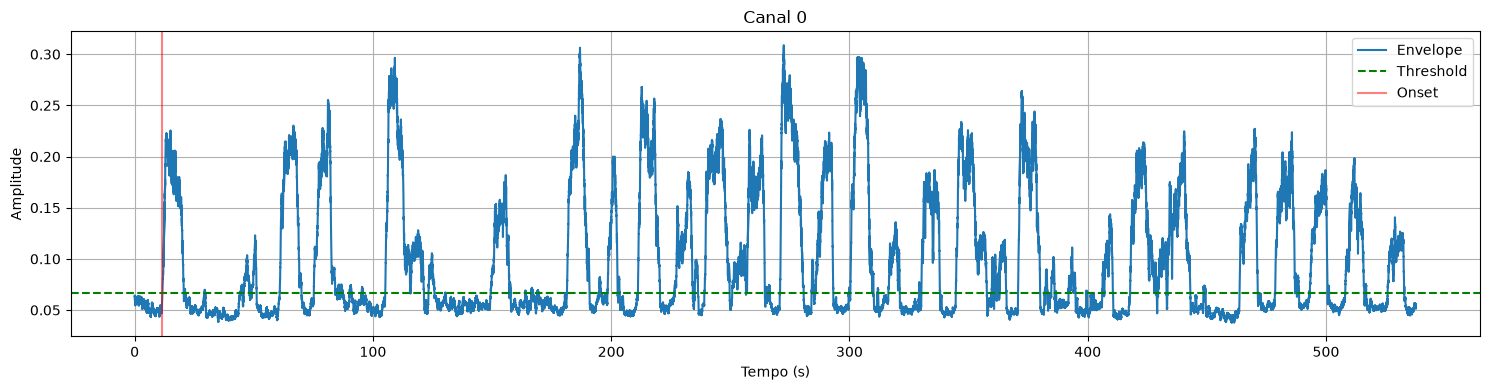

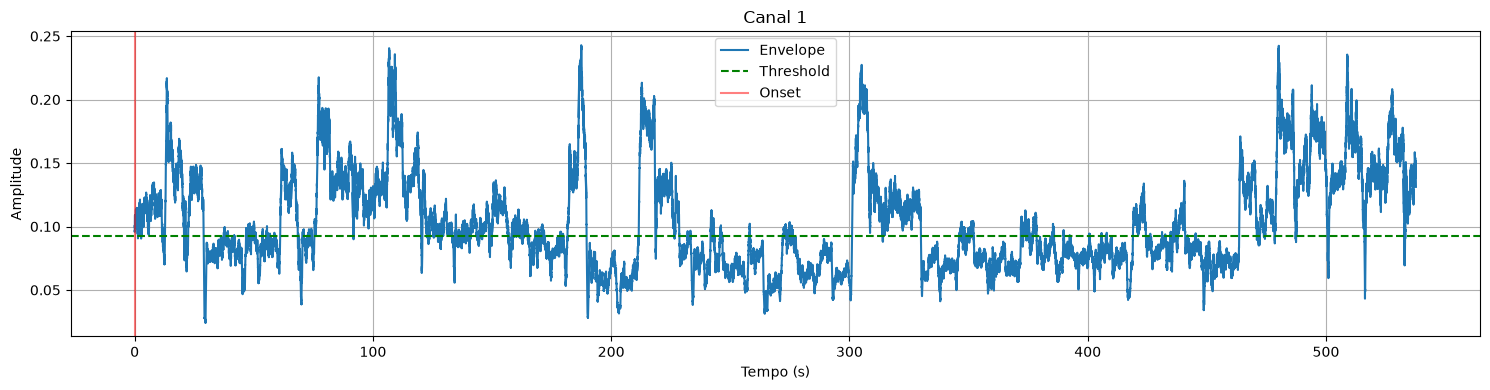

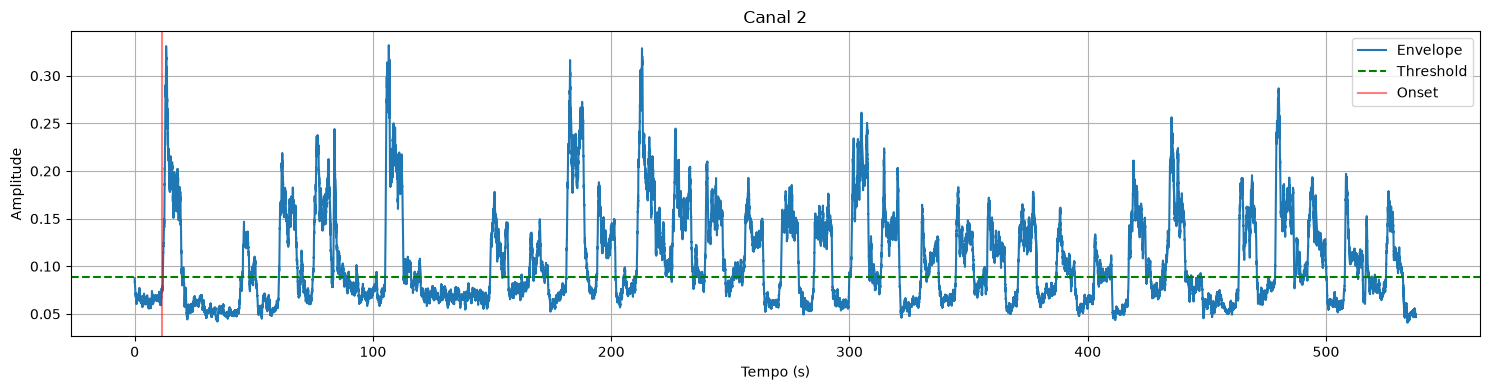

Valores encontrados: [11370     0 11530]
Mediana: 11370.0
Tem onset próximo de zero? True
Tem outlier? True
Valores válidos: [11370 11530]
Onset mínimo válido: 11370
Cut: 8527
Novo tamanho: 529733


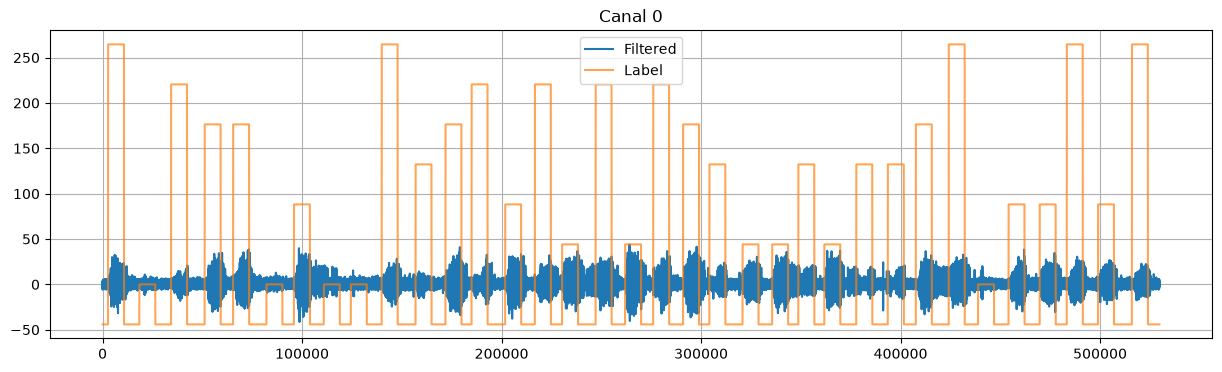

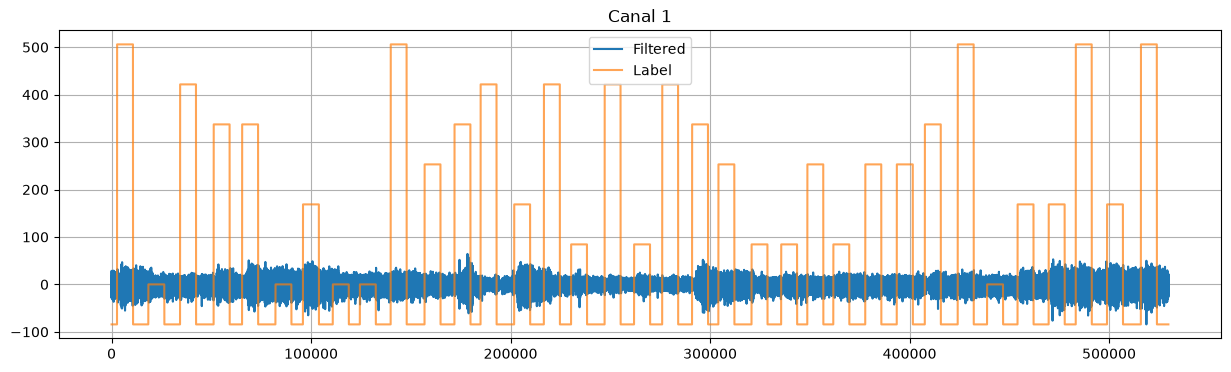

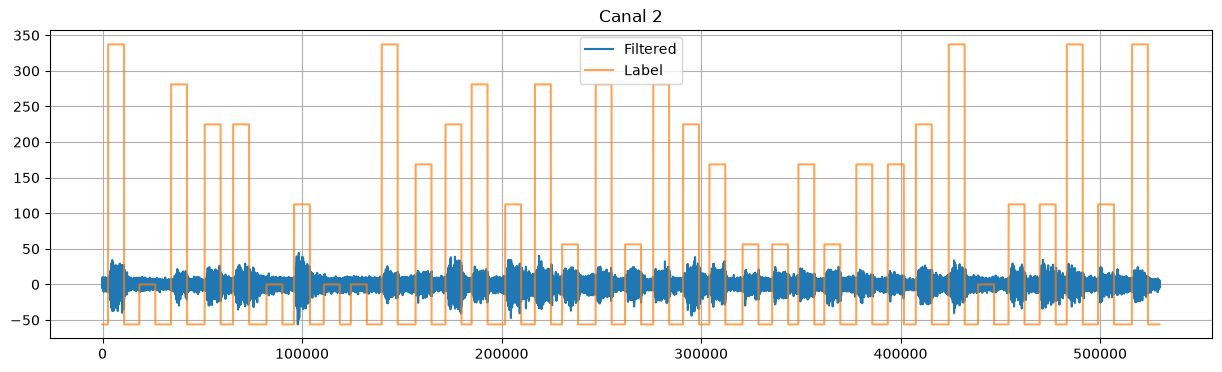

,set,event_id,label,event_name,signals_shape,n_channels,n_samples,duration_ms,start_idx,end_idx,ch1_shape,ch2_shape,ch3_shape
0,train,1,0,Relaxamento,"(3, 5980)",3,5980,7980.0,83133,89113,"(5980,)","(5980,)","(5980,)"
1,train,1,1,Peito,"(3, 6010)",3,6010,8010.0,262893,268903,"(6010,)","(6010,)","(6010,)"
2,train,4,5,Peito_Pescoço,"(3, 5970)",3,5970,7970.0,276993,282963,"(5970,)","(5970,)","(5970,)"
3,train,1,3,Pescoço,"(3, 6000)",3,6000,8000.0,305153,311153,"(6000,)","(6000,)","(6000,)"
4,train,1,4,Peito_Trapézio,"(3, 6020)",3,6020,8020.0,66413,72433,"(6020,)","(6020,)","(6020,)"
5,train,0,1,Peito,"(3, 5970)",3,5970,7970.0,231323,237293,"(5970,)","(5970,)","(5970,)"
6,train,3,5,Peito_Pescoço,"(3, 5990)",3,5990,7990.0,248133,254123,"(5990,)","(5990,)","(5990,)"
7,train,4,6,Trapézio_Pescoço,"(3, 6000)",3,6000,8000.0,516933,522933,"(6000,)","(6000,)","(6000,)"
8,train,3,2,Trapézio,"(3, 6010)",3,6010,8010.0,470713,476723,"(6010,)","(6010,)","(6010,)"
9,train,0,3,Pescoço,"(3, 5980)",3,5980,7980.0,157873,163853,"(5980,)","(5980,)","(5980,)"



Skewness média absoluta: 0.8136
Usando RobustScaler (dados assimétricos)

COMB 0: [0, 1]
  -> train size: 956
  -> classes: [0 1]
[LightGBM] [Info] Number of positive: 477, number of negative: 479
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000455 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 765
[LightGBM] [Info] Number of data points in the train set: 956, number of used features: 3
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.498954 -> initscore=-0.004184
[LightGBM] [Info] Start training from score -0.004184
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGB

Learning rate set to 0.010106
0:	learn: 0.6730320	total: 150ms	remaining: 2m 29s
1:	learn: 0.6531965	total: 154ms	remaining: 1m 16s
2:	learn: 0.6352130	total: 158ms	remaining: 52.4s
3:	learn: 0.6164775	total: 161ms	remaining: 40.1s
4:	learn: 0.5985468	total: 165ms	remaining: 32.8s
5:	learn: 0.5816764	total: 168ms	remaining: 27.9s
6:	learn: 0.5651201	total: 172ms	remaining: 24.4s
7:	learn: 0.5515296	total: 175ms	remaining: 21.7s
8:	learn: 0.5355734	total: 177ms	remaining: 19.5s
9:	learn: 0.5220086	total: 182ms	remaining: 18s
10:	learn: 0.5079399	total: 185ms	remaining: 16.6s
11:	learn: 0.4940840	total: 189ms	remaining: 15.5s
12:	learn: 0.4803338	total: 193ms	remaining: 14.7s
13:	learn: 0.4665702	total: 198ms	remaining: 14s


14:	learn: 0.4533635	total: 202ms	remaining: 13.3s
15:	learn: 0.4409674	total: 205ms	remaining: 12.6s
16:	learn: 0.4297030	total: 208ms	remaining: 12s
17:	learn: 0.4182250	total: 212ms	remaining: 11.5s
18:	learn: 0.4056275	total: 215ms	remaining: 11.1s
19:	learn: 0.3943955	total: 218ms	remaining: 10.7s
20:	learn: 0.3844142	total: 221ms	remaining: 10.3s
21:	learn: 0.3745145	total: 224ms	remaining: 9.94s
22:	learn: 0.3652860	total: 227ms	remaining: 9.65s
23:	learn: 0.3551030	total: 230ms	remaining: 9.36s
24:	learn: 0.3462552	total: 233ms	remaining: 9.08s
25:	learn: 0.3379513	total: 236ms	remaining: 8.83s
26:	learn: 0.3298937	total: 239ms	remaining: 8.61s
27:	learn: 0.3219213	total: 242ms	remaining: 8.41s
28:	learn: 0.3141922	total: 245ms	remaining: 8.21s
29:	learn: 0.3067583	total: 248ms	remaining: 8.02s
30:	learn: 0.2999764	total: 251ms	remaining: 7.84s
31:	learn: 0.2936062	total: 254ms	remaining: 7.68s
32:	learn: 0.2875320	total: 258ms	remaining: 7.55s
33:	learn: 0.2804263	total: 261ms

72:	learn: 0.1476990	total: 388ms	remaining: 4.93s
73:	learn: 0.1459421	total: 392ms	remaining: 4.91s
74:	learn: 0.1441552	total: 395ms	remaining: 4.88s
75:	learn: 0.1424347	total: 398ms	remaining: 4.84s
76:	learn: 0.1406507	total: 401ms	remaining: 4.81s
77:	learn: 0.1393550	total: 404ms	remaining: 4.78s
78:	learn: 0.1376572	total: 408ms	remaining: 4.75s
79:	learn: 0.1360853	total: 411ms	remaining: 4.73s
80:	learn: 0.1345843	total: 414ms	remaining: 4.7s
81:	learn: 0.1328892	total: 417ms	remaining: 4.67s
82:	learn: 0.1313245	total: 420ms	remaining: 4.64s
83:	learn: 0.1300427	total: 424ms	remaining: 4.62s
84:	learn: 0.1286297	total: 427ms	remaining: 4.59s
85:	learn: 0.1272097	total: 430ms	remaining: 4.57s
86:	learn: 0.1258797	total: 433ms	remaining: 4.54s
87:	learn: 0.1247220	total: 436ms	remaining: 4.51s
88:	learn: 0.1238903	total: 439ms	remaining: 4.49s
89:	learn: 0.1228114	total: 442ms	remaining: 4.47s
90:	learn: 0.1218484	total: 445ms	remaining: 4.44s
91:	learn: 0.1211969	total: 448m

...

best_6_classes_Relaxamento_Peito_Trapézio_Peito_Trapézio_Peito_Pescoço_Trapézio_Pescoço_logistic_regression_accuracy
best_6_classes_Relaxamento_Peito_Trapézio_Pescoço_Peito_Pescoço_Trapézio_Pescoço_xgboost_accuracy


best_6_classes_Relaxamento_Peito_Trapézio_Pescoço_Peito_Trapézio_Peito_Pescoço_mlp_accuracy


best_6_classes_Relaxamento_Peito_Trapézio_Pescoço_Peito_Trapézio_Trapézio_Pescoço_lightgbm_accuracy


best_6_classes_Relaxamento_Trapézio_Pescoço_Peito_Trapézio_Peito_Pescoço_Trapézio_Pescoço_catboost_accuracy


best_7_classes_Relaxamento_Peito_Trapézio_Pescoço_Peito_Trapézio_Peito_Pescoço_Trapézio_Pescoço_catboost_accuracy


In [53]:
# from emg_automl import automl

# -----------------------------
# DATA CONFIG
# -----------------------------
data_cfg = DataConfig(
    data_file='11-08-2026_14-59-29.txt',
    data_path='.',
    participant="A1_A2_A3_A4",
    label_names=["Relaxamento","Peito","Trapézio","Pescoço","Peito_Trapézio","Peito_Pescoço", "Trapézio_Pescoço"],
    channel_names=["Peito", "Trapézio", "Pescoço"]
)

# -----------------------------
# PREPROCESSING CONFIG
# -----------------------------
preprocessing_cfg = PreprocessingConfig(
    fs=1000,
    lowcut=30,
    highcut=450,
    notch_freqs=(60,),
    Q=30,
    signal_padding=0.2,
    butter_order=4,
    adc_pin=34,
)

events_cfg = EventsConfig(
    smooth_win_size=500,
    onset_sustain_ms=1500,
    onset_tol_ratio=0.20,
    pre_onset_removal_ratio=0.25,
    event_pad_ms=-1000
)

# -----------------------------
# WINDOWING CONFIG
# -----------------------------
windowing_cfg = WindowingConfig(
    test_size=0.2,
    window_ms=50,
    overlap=0.0
)

# -----------------------------
# FEATURE CONFIG
# -----------------------------
feature_cfg = FeatureConfig(
    features=[
        "RMS"
    ],
    #tsfresh = False
    return_dataframe=True
)

# -----------------------------
# NORMALIZE
# -----------------------------
normalize_cfg = NormalizeConfig(
    scale_y=False
)

# -----------------------------
# CLASSIFICATION CONFIG
# -----------------------------
classify_cfg = ClassificationConfig(
    algorithms=[
        "lightgbm",
        "xgboost",
        "catboost",
        "random_forest",
        "extra_trees",
        "svm",
        "mlp",
        "logistic_regression"
    ],
    sort_by="accuracy"
)

# -----------------------------
# RUN AUTOML
# -----------------------------
results = automl(
    data_cfg=data_cfg,
    preprocessing_cfg=preprocessing_cfg,
    events_cfg=events_cfg,
    windowing_cfg=windowing_cfg,
    feature_cfg=feature_cfg,
    normalize_cfg=normalize_cfg,
    classify_cfg=classify_cfg,

    run_preprocessing=True,
    run_windowing=True,
    run_features=True,
    run_normalization=True,
    run_classification=True,
    run_plots=True
)